# IEEE-CIS — Graf Tabanlı Öznitelik Mühendisliği (sızıntısız pipeline)

Bu notebook, BankSim üzerinde kurulan sızıntısız protokolü gerçek bir e-ticaret
dolandırıcılık veri setine (IEEE-CIS, 590.540 işlem, %3.5 fraud) taşır.


| Deney | Bu notebook'ta |
|---|---|
| **Hedef sızıntısı** (`community_fraud_rate` tüm veriden hesaplanıyordu) | Tüm öznitelikler — graf, topluluk, fraud oranı, aggregate, imputasyon, kategorik kodlama — **her fold'un yalnızca eğitim kısmından** öğrenilir (Bölüm 5) |
| **Look-ahead bias** | Graf yalnızca eğitim işlemlerinden kurulur; test varlıkları grafa girmez |
| **Entity leakage** (aynı müşteri iki fold'da) | `card1` bazlı GroupKFold protokolü (Bölüm 9) |
| **Zamansal bütünlük** | Out-of-time bölme, `TransactionDT` %80 kesim (Bölüm 10) |
| **Sınıf dağılımının çarpıtılması** | Alt örneklem **rastgele**, stratifiye değil → prevalans korunur (Bölüm 3) |
| **Simülatör/veri artefaktı** (PaySim dersi) | Deney öncesi **artefakt denetimi**: tek öznitelik AUC taraması, kural dedektörü, dejenerasyon kontrolü (Bölüm 7) |
| **Graf katkısı belirsiz** | **Set D = A + yalnızca graf** ile saf katkı izole edilir |
| **İstatistiksel anlamlılık yok** | Fold bazlı eşleştirilmiş t-testi, Wilcoxon, Cohen's d (Bölüm 12) |
| **Metrikler eksik** | PR-AUC, FPR, precision@k, recall@k, confusion matrix (Bölüm 6) |
| **Öznitelik atıfı gösterilmemiş** | SHAP, kategori bazında katkı payı (Bölüm 13) |
| **Zaman karmaşıklığı ölçülmemiş** | Algoritma bazlı çıkarım süreleri, işlem/saniye verimi (Bölüm 14) |
| **"Gradient Augmented" terimi yanlış** | **Gradient Boosted Decision Trees** (histogram tabanlı uygulama) |
| **Tekrarlanabilirlik detayları eksik** | Tüm hiperparametreler belgelenir; sızıntı öz-testi (Bölüm 8) |

## Keşif aşamasında doğrulananlar

Graf yapısı deney öncesi ölçüldü ve PaySim'deki dejenerasyonun burada olmadığı
teyit edildi:

| Ölçüt | BankSim | **IEEE-CIS** | PaySim (reddedilen) |
|---|---|---|---|
| Kenar/Düğüm | 6.24 | **3.03** | 0.51 |
| En büyük bileşen | tek | **%99.2** | %0.0 |
| Tek işlemli varlık | %0 | **%25.4** | %100 |
| `card1` medyan işlem | — | **4** | 1 |

## Revizyon günlüğü

| Kod | Değişiklik | Gerekçe |
|---|---|---|
| **A1** | `community_fraud_rate` eğitim satırları için iç K-fold ile **out-of-fold** hesaplanıyor; test satırları tüm eğitim etiketlerinden. Yumuşatma (`TE_SMOOTHING`) eklendi. P2'de iç bölme varlık bazlı (`te_group_col`). | Eski sürümde eğitim satırları kendi etiketini içeren oranı görüyordu (in-sample target encoding): eğitim/test dağılım uyumsuzluğu ve özniteliğe aşırı güven. |
| **A1** | Checkpoint dizini `PIPELINE_VERSION` ile sürümlendi. | `RESUME=True` eski (A1 öncesi) checkpoint'leri yükleyip yeni sonuçlarla karıştırmasın. |
| **A1** | Grafta olmayan (cold-start) kartlar artık `community = -1` grubunun oranını değil, eğitim önselini alıyor. | `-1` LCC dışındaki *görülmüş* düğümleri temsil ediyordu; görülmemiş kartlar yanlışlıkla bu grubun oranıyla eşleşiyordu. |
| **Fix** | SHAP hücresi `Xtr_s`/`Xte_s`'i kendisi üretiyor; BankSim karşılaştırması sabit sayı yerine `shap_importance.csv`'den okunuyor. | `Xtr_s` yalnızca `fit_predict` içinde yereldi → `NameError`. Sabit %67.0 değeri makaledeki %63.6 ile çelişiyordu. |
| **A1 sonuç** | Tam grid çalıştırıldı. BankSim P1/P3 sonuçları önceki sürümle neredeyse aynı (ör. RF Set C 0.8705 → 0.8711), P2 ortalama D–A −0.3530 → −0.3531. | BankSim eğitim grafında Louvain yalnızca **3 topluluk** buluyor; 3 düzeyli bir oranda in-sample etki ihmal edilebilir. Düzeltme yine de gerekliydi; artık bulguların bu hataya karşı sağlam olduğu gösterilebiliyor. |
| **A2** | Görülmeyen varlıkların graf ve davranışsal öznitelikleri NaN üretilip tek bir politika ile dolduruluyor (`IMPUTE_POLICY`, varsayılan `row_median`; `legacy` eski davranışı aynen üretir). Türetilmiş oranlar (`amount_to_*_avg`) doldurmadan sonra hesaplanıyor. | Eski sürümde merkeziyet `0.0` (eğitimde hiç görülmeyen uç değer), davranışsal ise düğüm medyanı ile dolduruluyordu; iki grup farklı kurala tabiydi. |
| **A2** | Satır bazlı görülme bayrakları (`_*_seen`, öznitelik **değil**) ve `kappa` (değerlendirme satırlarının eğitim grafında olan oranı) her fold için kaydediliyor. | Makaledeki κ artık doğrudan ölçülüyor; router ve κ-duyarlı eğitim için altyapı. |
| **A2** | Yeni hücre: *A2 duyarlılık testi* (P2, `legacy` vs `row_median`). | Cold-start çöküşünün ne kadarının imputasyon seçimine bağlı olduğunu ölçer. |
| **Fix** | Hesaplama maliyeti hücresindeki sabit `BankSim: 12.049 işlem/saniye` satırı `timing_analysis.json`'dan okunuyor. | Güncel BankSim çıktısı 26.174 işlem/saniye; sabit değer eskimişti. |
| **A2 sonuç** | Duyarlılık testi (BankSim P2, fold 1): Set D F1 `legacy` → `row_median`: DT 0.210 → 0.676, LightGBM 0.279 → 0.614; LightGBM PR-AUC 0.553 → 0.822. LR'de PR-AUC iki politikada **aynı**, yalnızca F1 değişiyor. IEEE'de farklar ≤ 0.025. | BankSim'deki cold-start çöküşünün büyük kısmı imputasyon artefaktı (0.0 = eğitimde görülmeyen uç değer). LR'de imputasyon tüm cold satırların skorunu aynı miktarda kaydırıyor: sıralama değişmiyor, eğitimde seçilen eşik transfer olmuyor (kalibrasyon kayması). IEEE eğitiminde zaten imputed satırlar (addr1 eksik) olduğundan etki küçük. |
| **A3** | Point-in-time öznitelikler D bölümüne (rolling-origin) ertelendi. | Aynı altyapıyı (zamana göre artımlı graf/aggregate) gerektiriyor. |
| **A4** | Kimlik benzeri öznitelikler setlerden çıkarıldı (`A4_DROP`). Eski listeler `FEATURES_A_LEGACY`, `GRAPH_FEATS_LEGACY` olarak tutuluyor. | Varlık anahtarı P1'de ezbere izin veriyor, P2'de sabit; Louvain etiketleri keyfi ve fold'dan fold'a değişiyor, sayısal büyüklükleri anlamsız. |
| **A4** | Yeni hücre: *A4 hızlı kontrol* (P1/P2 fold 1, eski vs A4 listeleri). | Çıkarılan özniteliklerin etkisini ölçer; makalede tek cümle ile raporlanabilir. |
| **A4** | IEEE: `card1` (P2'nin gruplama anahtarı) ve `card1_community`, `addr1_community` çıkarıldı. `card2/3/5`, `addr1/2` kart/adres öznitelikleri olarak kaldı. Set boyutları A 23→22, C 49→46, D 36→33. | `card1` hem gruplama anahtarı hem sayısal öznitelikti; P2'de tüm test değerleri eğitimde görülmemiş kodlar. |
| **A4 sonuç** | Hızlı kontrol (fold 1): `card1` ve topluluk etiketlerini çıkarmanın etkisi küçük (|ΔF1| ≤ 0.04); P2'de Set A DT F1 0.210 → 0.247. | `card1` P2'de görülmemiş kodlar taşıyordu. |
| **A6** | DENETİM 1 ve 2 hücreleri, makale Table 2 tanımlarıyla birebir `artefact_audit` ile değiştirildi: kategorik öznitelikler de taranıyor (OOF oran), 4 elle seçilmiş kural yerine tek ve iki koşullu (AND/OR) kural taraması, ρ1, λ, γ hesaplanıyor. `scan`, `rule_df` değişken adları korundu. | Makale "her tek ve iki koşullu kural tarandı" diyordu; kod yalnızca 4 kural deniyordu. |
| **A6 sonuç** | IEEE-CIS denetimi geçti: a* = 0.691 (C4), F1* = 0.341 (iki koşullu kural), ρ1 = 0.348, λ = 4.52, γ = 0.999. | Makalede F1* = 0.180, ρ1 = 0.25, λ = 3.03 yazıyordu; bunlar 4 elle seçilmiş kuraldan ve farklı bir hesaplamadan geliyordu, güncellenmeli. |
| **A7** | Varlık `card1` yerine `uid = card1 + addr1 + D1n` (`ENTITY_COL`). P2 gruplaması, davranışsal aggregate'ler (`ent_*`), `community_fraud_rate`, κ ve denetim bu varlık üzerinden. Graf: uid → {card1, addr1, P_emaildomain}; düğüm öznitelikleri uid, card1 ve addr1 için. | `card1` binlerce kartı kapsayan bir kart numarası parçası; "entity-grouped" protokol gerçek bir müşteri gruplaması değildi. |
| **A7** | Alt örneklem varlık bazlı (`SUBSAMPLE_MODE='entity'`): rastgele varlıkların TÜM işlemleri alınıyor. | Rastgele satır örneklemi her varlığın geçmişini ~%34'e inceltiyor; derece, aggregate ve κ yapay olarak düşüyordu. |
| **Fix** | `clustering` öznitelikleri varsayılan olarak hesaplanmıyor (`CLUSTERING_MODE='drop'`). | Graf iki parçalı (her kenar farklı tipte iki düğüm arasında) → klasik clustering katsayısı her düğümde 0; öznitelikler sabitti. |
| **A7 sonuç (IEEE, tam grid)** | uid ile: 217.850 varlık (ort. 2.71, medyan 1 işlem). P1 κ = 0.76, P3 κ = 0.44 (gerçek veride rastgele CV'de bile κ < 1). P1: RF Set C F1 0.539 (eski 0.425); D–A 8/10 modelde anlamlı (düz t-testi), ort. +0.029. P2 (κ = 0): D–A ≈ 0. P3: D–A F1'de çoğu modelde negatif (ort. ≈ −0.05) ama PR-AUC'de ≈ 0 / pozitif (LightGBM 0.258 → 0.267). Denetimde **C3 kaldı** (ρ1 = 0.584 > 0.50). | P3'teki F1 kaybı sıralamadan değil, eğitim (κ = 1) ile test (κ = 0.44) arasındaki eşik/kalibrasyon kaymasından geliyor. C3 başarısızlığı: IEEE-CIS'te graf için *boş* sonuç bilgilendirici değil (pozitif sonuçlar etkilenmez). |
| **Karar** | BankSim'in rolü: ana veri değil, (i) artefakt denetiminin yakaladığı kısa yol veri seti örneği ve (ii) sızıntı şişmesinin kontrollü ölçümü. Ana sonuçlar IEEE-CIS ve eklenecek gerçek graf verisinde. | A6: BankSim C1 ve C2'den kaldı. |
| **Sürüm** | `CHECKPOINT_VERSION` `PIPELINE_VERSION`'dan ayrıldı (`'A7'`). Öznitelik/model tanımı değişmeyen revizyonlarda mevcut sonuçlar yeniden yükleniyor. Tamamlanan A1/A2/A4 kontrolleri varsayılan olarak kapalı. | B revizyonu yalnızca yeni deneyler ve analizler ekliyor; ana grid'in yeniden koşulmasına gerek yok. |
| **Sızıntı enjeksiyonu** | Yeni hücre: dört sızıntı yolu (graf, aggregate, topluluk oranı, eşik) sızıntısız pipeline'a tek tek ve birlikte geri ekleniyor; her yolun F1/PR-AUC şişmesi aynı fold ve modellerde ölçülüyor. | Makaledeki "0.936 → 0.871, tek bir sızıntı yolu" iddiası, BankSim'de yalnızca 3 topluluk olduğu için desteklenemiyordu; yerine ölçülmüş, yol bazlı tahmin. |
| **B9** | Düzeltilmiş yeniden örnekleme t-testi (Nadeau & Bengio 2003) + Holm düzeltmesi; P1 ve P2 için C–B, D–A, B–A, F1 ve PR-AUC. Eski düz t-testi karşılaştırma için tutuldu. | CV fold'ları bağımsız değil; düz t-testi p-değerlerini olduğundan küçük veriyordu. 10 model için çoklu karşılaştırma düzeltmesi yoktu. |
| **B10** | SMOTETomek artık diğer yöntemlerle aynı hedef oranı (`SAMPLING_RATIO = 1/3`) kullanıyor; yalnızca SMOTETomek yeniden koşuluyor. | Eski sürümde SMOTETomek varsayılan 1:1 ile çalışıyordu; karşılaştırma eşit koşullarda değildi. |
| **Makale metni** | Kodla çelişen ifadeler düzeltilecek: SVM "RBF" değil doğrusal (`LinearSVC` + kalibrasyon); eşik "eğitim partisyonunda" değil, eğitim fold'undan ayrılan %20 iç doğrulamada seçilip model tüm fold'la yeniden eğitiliyor; Algoritma 1 satır numarası; κ değerleri ölçülen değerlerle (BankSim P1 = 1.000; IEEE uid P1 = 0.76, P3 = 0.44); "tüm veri setleri denetimi geçti" ifadesi; clustering maliyet analizi; denetim tablosu sayıları. | B10, B12, B13, A6. |
| **A8** | Güçlü baseline: `A_full` = tüm sayısal ham alanlar (V, C, D, id_ dahil) + kategorik kodlar; LightGBM ile P1/P2/P3'te A/B/C/D_full. Ayrı checkpoint etiketleri (`A8_P*`). | Set A kasıtlı olarak dardı; graf katkısının güçlü baseline üzerinde de var olup olmadığı ölçülmemişti. |
| **C** | Çözüm katmanı: (1) **κ-duyarlı eğitim** — eğitim varlıklarının (1 − κ̂) kadarının varlık tarafı öznitelikleri (varlık düğümü merkeziyetleri, varlık aggregate'leri, topluluk oranı) görülmeyen bir varlığın alacağı değerlerle değiştirilir, `is_cold` göstergesi eklenir; κ̂ değerlendirme kümesinden etiketsiz hesaplanır. (2) **Router** — varlık grafta ise C/D modeli, değilse A modeli. Karşı taraf öznitelikleri her iki durumda korunur. | Standart eğitimde κ_train = 1; model doldurma değerlerini hiç görmüyor ve eşik test dağılımına taşınmıyor (A2, A4, A7 bulguları). |
| **C** | `run_protocol` yeni parametreler alıyor (`kappa_mask_sets`, `router_pairs`, `save_predictions`); varsayılanlar eski davranışı aynen koruyor. `compute_fold_features` cold değerleri `attrs['cold_values']` ile döndürüyor (öznitelik değerleri değişmedi → `CHECKPOINT_VERSION` aynı). | Mevcut A7 sonuçları geçerliliğini koruyor. |
| **C** | Yeni hücreler: *C deneyi* (3 protokol, ayrı etiketler `C_P*`), *κ'ya göre ayrılmış metrikler* (görülen / görülmeyen varlıklar, kaydedilen tahminlerden), *imputasyon değişmezlik testi* (`legacy` vs `row_median`). | Çözümün hangi alt grupta kazanç sağladığını ve A2'deki duyarlılığı giderip gidermediğini ölçer. |
| **R1** | Varlık bazlı alt örneklem deterministik: varlıklar `sample()` öncesi kimliğe göre sıralanıyor; satırlar `TransactionDT`, `TransactionID` ile kararlı sıralanıyor. Örneklem parmak izi (satır, fraud, varlık sayısı, TransactionID SHA-1) checkpoint klasörüne yazılıyor ve sonraki oturumlarda doğrulanıyor. `CHECKPOINT_VERSION = 'R1'` (yeni örneklem → tüm grid bir kez yeniden koşulur). | v8_C oturumunda örneklem prevalansı %3.575, önceki oturumda %3.399 çıktı (aynı varlık sayısı): `value_counts` eşit sayılı varlıkların sırasını sabit vermiyor. Sonuçlar nitel olarak tutarlıydı ama birebir yeniden üretilemiyordu. |
| **R1 sonuç** | Dondurulan örneklem: 200.000 işlem, 6.764 fraud (%3.382), 73.965 varlık, TransactionID SHA-1 `8e8c441d…`. P1 D–A F1 +0.031 (Holm 6/10), P2 −0.023 (0/10), P3 −0.012. P1'de C–B F1 Holm sonrası 0/10 (düz t-testi 5/10). Router C\|A ortalama F1: P1 0.466 (A 0.394), P3 0.298 (A 0.278). κ-mask P3'te görülen alt gruptaki kazancı siliyor (PR-AUC C 0.352 → κ-mask 0.181). A8 P3 D_full–A_full PR-AUC +0.074 (önceki örneklemde +0.028). | Bu örneklemin sayıları makalede kullanılacak. Tek zamansal kesimin tahmini örnekleme duyarlı → P4. |
| **D** | κ-ayrılmış tablolar için alt küme boyutu ve pozitif sayısı (`kappa_counts`, `kappa_stratified`); `KAPPA_MIN_POS` altındaki alt kümeler "güvenilir değil" olarak işaretleniyor. | Küçük pozitif sayılı alt kümede PR-AUC yorumlanamaz (Elliptic P3 görülen alt grubu: 5 pozitif). |
| **D** | **P4 rolling-origin:** genişleyen pencere, kesimler `TransactionDT` kantillerinden (`P4_ORIGINS_Q`, ufuk `P4_HORIZON_Q`). Aynı fold'larda dar (A, B, C, D) ve güçlü (A_full, B_full, C_full, D_full) setler, κ-mask (C, C_full), router (C\|A, D\|A, C_full\|A_full, D_full\|A_full); LightGBM + XGBoost. Farklar origin bazında "ortalama ± std (kazanan origin / toplam)" olarak raporlanıyor; rolling fold'lar değiştirilebilir olmadığından düzeltilmiş t-testi uygulanmıyor. Etiket `R_P4`; `CHECKPOINT_VERSION` aynı (örneklem ve öznitelikler değişmedi). | Editörün "tek statik zamansal bölme" eleştirisi IEEE-CIS için de; A8 P3 sonucunun tek fold'a bağlı olup olmadığı. |
| **D sonuç** | Yeni Colab oturumunda örneklem parmak izi birebir eşleşti (SHA-1 `8e8c441d…`); P1, P3 ve ağaç modelleri önceki koşuyla aynı sayıları verdi. MLP ve LR'de küçük farklar (donanıma bağlı BLAS). **P2 fold'ları farklı çıktı:** eski sklearn GroupKFold eşit boyutlu grupları kararsız sıralıyor. | Örneklem düzeltmesi (R1) çalışıyor; P2 için ayrı düzeltme gerekli → D1. |
| **D sonuç** | **IEEE P4 (5 origin, LightGBM / XGBoost, PR-AUC):** dar baseline D–A +0.043 / +0.041 (5/5, 5/5 origin), Router C\|A–A +0.075 / +0.069 (5/5, 5/5); güçlü baseline D_full–A_full +0.017 / +0.015 (3/5, 4/5), **Router C_full\|A_full–A_full +0.040 / +0.029 (5/5, 5/5)**. κ-mask her iki baseline'da zararlı (C_full: 0/5, 2/5). A8 P3'teki +0.074 tek fold'un aşırı tahminiydi; origin bazında D_full–A_full 0.004–0.029. Görülen alt küme (878 pozitif): A_full 0.454 → C_full 0.605; görülmeyen (2.636 pozitif): 0.530 → 0.512. | Güçlü baseline üzerinde de kazanç görülen varlıklarda; router bunu kayıpsız topluyor. |
| **D1** | `GroupKFoldDet`: sklearn ≥ 1.7 GroupKFold ile aynı algoritma (kararlı sıralama), sürüm ve donanımdan bağımsız. P2 bölmesi, P2 iç OOF bölmesi ve A1/A2/A4 kontrolleri buna geçti. P2 bölme parmak izi checkpoint klasörüne yazılıyor; uyuşmazsa `P2_group`, `A8_P2`, `C_P2` checkpoint'leri silinip yeniden koşuluyor. `USE_DRIVE` parametresi. | P2 sonuçlarının oturumdan oturuma birebir yeniden üretilebilmesi. |


## 1. Kurulum ve Yapılandırma

In [1]:
import json
# pip install pandas numpy networkx python-louvain scikit-learn xgboost lightgbm shap scipy matplotlib seaborn

import pandas as pd, numpy as np, networkx as nx
import time, warnings, gc, json, os
import matplotlib.pyplot as plt
import seaborn as sns
from community import community_louvain
from scipy import stats

from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, precision_recall_curve, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')

# ==================== YAPILANDIRMA ====================
SEED = 42
N_FOLDS = 5
BETWEENNESS_K = 300
TEMPORAL_QUANTILE = 0.80        # kesif asamasinda dogrulandi

# Hiz / tamlik dengesi
#   SUBSAMPLE_N=200000 + FAST_MODE=True  -> ~2 saat   (ilk deneme)
#   SUBSAMPLE_N=None   + FAST_MODE=False -> ~6-8 saat (nihai sonuc)
FAST_MODE   = True
SUBSAMPLE_N = 200000            # None -> tam veri (590.540)

KNN_TRAIN_CAP  = 50000          # KNN kuadratik olceklenir
SAMPLING_FOLDS = 3              # sinif dengeleme bolumu fold sayisi

# ==================== A7 — VARLIK TANIMI ====================
# card1 tek bir kart degil, kart numarasinin bir parcasidir (binlerce karti kapsar).
# 'uid' = card1 + addr1 + D1n  (D1n = islem gunu - D1 = kartin baslangic gunu):
# IEEE-CIS literaturunde musteri kimligi icin yaygin kullanilan yaklasim.
ENTITY_COL     = 'uid'                       # 'uid' | 'card1' (eski davranis)
UID_PARTS      = ['card1', 'addr1', 'D1n']
SUBSAMPLE_MODE = 'entity'                    # 'entity': varlik bazli (gecmisler bolunmez) | 'row' (eski)
SUBSAMPLE_PREV_TOL = 0.005                   # alt orneklem prevalans toleransi

# Graf: varlik (uid) -> paylasilan nitelikler (kart grubu, adres bolgesi, e-posta alani).
if ENTITY_COL == 'uid':
    GRAPH_RELATIONS = [('uid', 'card1'), ('uid', 'addr1'), ('uid', 'P_emaildomain')]
    NODE_ENTITIES   = ['uid', 'card1', 'addr1']        # oznitelik cikarilacak dugum tipleri
else:
    GRAPH_RELATIONS = [('card1', 'addr1'), ('card1', 'P_emaildomain')]
    NODE_ENTITIES   = ['card1', 'addr1']
# Varlik bazli 'unique' aggregate'leri: varligin kendi parcalari sabit olacagindan dislanir
ENT_UNIQUE_COLS = [c for c in ['card1', 'addr1', 'P_emaildomain']
                   if c != ENTITY_COL and not (ENTITY_COL == 'uid' and c in UID_PARTS)]

# Vesta'nin kendi sayim oznitelikleri (C1-C14) Set A'ya DAHIL EDILMEZ.
# Gerekce: bunlar zaten toplulastirilmis oznitelikler; Set A'ya konursa
# davranissal katmanin (Set B) marjinal katkisi yapay olarak bastirilir.
# Ayri bir referans seti olarak raporlanir.
INCLUDE_VESTA_C_IN_A = False

# ==================== CHECKPOINT ====================
PIPELINE_VERSION = 'D1'   # her revizyon blogunda guncelle -> eski checkpoint'ler karismaz
CLUSTERING_MODE  = 'drop'         # Fix: 'drop' | 'bipartite' (Latapy) | 'standard' (iki parcali grafta hep 0)
IMPUTE_POLICY    = 'row_median'   # A2: 'row_median' | 'legacy' (gorulmeyen varlik imputasyonu)
CHECKPOINT_VERSION = 'R1'   # oznitelik/model tanimi DEGISMEDIKCE sabit -> mevcut sonuclar yeniden yuklenir
CHECKPOINT_DIR = f'checkpoints_ieee_{CHECKPOINT_VERSION}'
RESUME = True
USE_DRIVE = True    # Colab oturumlari arasinda checkpoint'leri korur
if USE_DRIVE:
    from google.colab import drive; drive.mount('/content/drive')
    CHECKPOINT_DIR = '/content/drive/MyDrive/ieee_checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
np.random.seed(SEED)
pd.set_option('display.width', 200)

print(f'FAST_MODE={FAST_MODE}  SUBSAMPLE_N={SUBSAMPLE_N}  N_FOLDS={N_FOLDS}')
print(f'ENTITY_COL={ENTITY_COL}  SUBSAMPLE_MODE={SUBSAMPLE_MODE}  CLUSTERING_MODE={CLUSTERING_MODE}')
print(f'GRAPH_RELATIONS={GRAPH_RELATIONS}')
print(f'CHECKPOINT_DIR={CHECKPOINT_DIR}  RESUME={RESUME}')

Mounted at /content/drive
FAST_MODE=True  SUBSAMPLE_N=200000  N_FOLDS=5
ENTITY_COL=uid  SUBSAMPLE_MODE=entity  CLUSTERING_MODE=drop
GRAPH_RELATIONS=[('uid', 'card1'), ('uid', 'addr1'), ('uid', 'P_emaildomain')]
CHECKPOINT_DIR=/content/drive/MyDrive/ieee_checkpoints  RESUME=True


## 2. Veri Yükleme

In [2]:
def reduce_mem(df, verbose=True):
    '''float64/int64 -> daha kucuk dtype. Tamamen bos sutunlar atlanir.'''
    start = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            continue
        s = df[col]
        if s.isna().all():
            continue
        c_min, c_max = s.min(), s.max()
        if pd.isna(c_min) or pd.isna(c_max):
            continue
        if pd.api.types.is_integer_dtype(s):
            if c_min >= np.iinfo(np.int32).min and c_max <= np.iinfo(np.int32).max:
                df[col] = s.astype(np.int32)
        else:
            if c_min >= np.finfo(np.float32).min and c_max <= np.finfo(np.float32).max:
                df[col] = s.astype(np.float32)
    end = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(f'  Bellek: {start:.0f} MB -> {end:.0f} MB')
    return df


t0 = time.time()
tx  = reduce_mem(pd.read_csv('train_transaction.csv'))
idf = reduce_mem(pd.read_csv('train_identity.csv'))
df_full = tx.merge(idf, on='TransactionID', how='left')
del tx, idf; gc.collect()
print(f'Yüklendi: {df_full.shape} ({time.time()-t0:.0f}s)')

# Butunluk kontrolu
CRITICAL = ['TransactionID','TransactionDT','TransactionAmt','isFraud']
nanc = df_full[CRITICAL].isna().sum()
if nanc.sum() > 0:
    print('Eksik değer temizleniyor:'); print(nanc[nanc>0].to_string())
    df_full = df_full.dropna(subset=CRITICAL).copy()
df_full['isFraud'] = df_full['isFraud'].astype(int)
assert set(df_full['isFraud'].unique()) <= {0,1}

FULL_PREVALENCE = df_full['isFraud'].mean()
print(f'Fraud: {df_full["isFraud"].sum():,} (%{FULL_PREVALENCE*100:.3f})')

  Bellek: 2062 MB -> 1206 MB
  Bellek: 143 MB -> 130 MB
Yüklendi: (590540, 434) (54s)
Fraud: 20,663 (%3.499)


## 3. Örneklem — Prevalans Korunarak

PaySim'de tüm fraud + sabit sayıda normal alınmasının sınıf
dağılımını çarpıttığını belirtmişti. Burada **rastgele** (stratifiye olmayan)
örneklem alınır; fraud oranı orijinal değerinde kalır.

In [3]:
# ---- A7: uid (alt orneklemden ONCE, tam veride) ----
df_full['D1n'] = (df_full['TransactionDT'] // 86400) - df_full['D1']
def _key_str(s):
    '''NaN-guvenli metin anahtari (pandas 2 ve 3 ile ayni sonuc).'''
    return s.astype(object).where(s.notna(), 'nan').map(str)
df_full['uid'] = _key_str(df_full[UID_PARTS[0]])
for _p in UID_PARTS[1:]:
    df_full['uid'] = df_full['uid'] + '_' + _key_str(df_full[_p])
_ec = df_full[ENTITY_COL].value_counts()
print(f'Varlik ({ENTITY_COL}): {len(_ec):,} tekil | islem/varlik ort={_ec.mean():.2f} medyan={_ec.median():.0f} '
      f'| tek islemli=%{(_ec == 1).mean()*100:.1f}')

if SUBSAMPLE_N and len(df_full) > SUBSAMPLE_N and SUBSAMPLE_MODE == 'entity':
    # varliklar rastgele sirada eklenir; bir varligin TUM islemleri alinir
    # R1: value_counts esit sayili varliklari oturumdan oturuma farkli sirada
    # verebiliyor -> once varlik kimligine gore deterministik siralanir.
    _ec_det = _ec.sort_index(kind='mergesort')
    _order = _ec_det.sample(frac=1.0, random_state=SEED)
    _keep  = _order.index[_order.cumsum().values <= SUBSAMPLE_N]
    df = (df_full[df_full[ENTITY_COL].isin(set(_keep))]
                 .sort_values(['TransactionDT', 'TransactionID'], kind='mergesort')
                 .reset_index(drop=True))
    print(f'Varlık bazlı örneklem: {len(df):,} satır, {len(_keep):,} varlık')
elif SUBSAMPLE_N and len(df_full) > SUBSAMPLE_N:
    df = (df_full.sample(n=SUBSAMPLE_N, random_state=SEED)
                 .sort_values('TransactionDT').reset_index(drop=True))
    print(f'Rastgele örneklem: {len(df):,} satır')
else:
    df = df_full.sort_values('TransactionDT').reset_index(drop=True)
    print(f'Tam veri: {len(df):,} satır')
del df_full; gc.collect()

print(f'  Fraud oranı — örneklem: %{df["isFraud"].mean()*100:.3f} '
      f'| orijinal: %{FULL_PREVALENCE*100:.3f}')
assert abs(df['isFraud'].mean() - FULL_PREVALENCE) < SUBSAMPLE_PREV_TOL, 'Prevalans kaymış!'
print('  -> Prevalans korundu.')

# ---- R1: orneklem parmak izi (farkli orneklemle checkpoint karismasin) ----
import hashlib
_fp = {
    'n_rows': int(len(df)),
    'n_fraud': int(df['isFraud'].sum()),
    'n_entities': int(df[ENTITY_COL].nunique()),
    'txid_sha1': hashlib.sha1(np.sort(df['TransactionID'].values).tobytes()).hexdigest(),
}
_fp_path = os.path.join(CHECKPOINT_DIR, 'sample_fingerprint.json')
if os.path.exists(_fp_path):
    _old_fp = json.load(open(_fp_path))
    assert _old_fp == _fp, (f'Orneklem checkpoint klasorundekiyle AYNI DEGIL!\n'
                            f'  kayitli: {_old_fp}\n  simdiki: {_fp}\n'
                            f'  -> CHECKPOINT_VERSION degistirin ya da klasoru temizleyin.')
    print(f'  Orneklem parmak izi checkpoint ile eslesti ({_fp["txid_sha1"][:12]}).')
else:
    json.dump(_fp, open(_fp_path, 'w'), indent=2)
    print(f'  Orneklem parmak izi kaydedildi: {_fp}')

# Varlik alanlari string'e cevrilir (graf dugum kimligi icin)
def node_key(entity):
    '''Graf dugum kimligi sutun adi.'''
    return f'{entity}__node'

for c in ['uid','card1','addr1','P_emaildomain','R_emaildomain']:
    if c in df.columns:
        df[node_key(c)] = c + '=' + df[c].astype(str)

TEMPORAL_CUT = df['TransactionDT'].quantile(TEMPORAL_QUANTILE)
print(f'\nZamansal kesim: TransactionDT = {TEMPORAL_CUT:,.0f}')
for lab, m in [('Eğitim', df.TransactionDT <= TEMPORAL_CUT),
               ('Test  ', df.TransactionDT >  TEMPORAL_CUT)]:
    s = df[m]
    print(f'  {lab}: n={len(s):,} fraud={s.isFraud.sum():,} (%{s.isFraud.mean()*100:.3f})')

Varlik (uid): 217,850 tekil | islem/varlik ort=2.71 medyan=1 | tek islemli=%57.5
Varlık bazlı örneklem: 200,000 satır, 73,965 varlık
  Fraud oranı — örneklem: %3.382 | orijinal: %3.499
  -> Prevalans korundu.
  Orneklem parmak izi checkpoint ile eslesti (8e8c441d9393).

Zamansal kesim: TransactionDT = 12,264,673
  Eğitim: n=160,000 fraud=5,489 (%3.431)
  Test  : n=40,000 fraud=1,275 (%3.188)


## 4. Ham Öznitelik Grupları

In [4]:
# --- Set A cekirdegi: dusuk eksiklikli, yorumlanabilir ham alanlar ---
A_NUMERIC_BASE = ['TransactionAmt','dist1']
A_CATEGORICAL  = ['ProductCD','card4','card6','P_emaildomain','R_emaildomain']
A_ID_NUMERIC   = ['card1','card2','card3','card5','addr1','addr2']

# D sutunlari: zaman deltalari. Yalnizca eksigi <%50 olanlar alinir.
D_ALL  = [f'D{i}' for i in range(1,16) if f'D{i}' in df.columns]
D_KEEP = [c for c in D_ALL if df[c].isna().mean() < 0.50]

# Vesta'nin kendi sayim oznitelikleri (referans seti icin)
C_COLS = [f'C{i}' for i in range(1,15) if f'C{i}' in df.columns]

df['TransactionAmt_log'] = np.log1p(df['TransactionAmt'])
df['hour'] = (df['TransactionDT'] // 3600) % 24
df['dayofweek'] = (df['TransactionDT'] // 86400) % 7

A_ENGINEERED = ['TransactionAmt_log','hour','dayofweek']

print(f'A sayısal temel   : {A_NUMERIC_BASE}')
print(f'A kategorik       : {A_CATEGORICAL}')
print(f'A kimlik-sayısal  : {A_ID_NUMERIC}')
print(f'A türetilmiş      : {A_ENGINEERED}')
print(f'D sütunları (<%50): {D_KEEP}  ({len(D_KEEP)}/{len(D_ALL)})')
print(f'Vesta C sütunları : {len(C_COLS)} adet (Set A dışında, referans seti için)')

A sayısal temel   : ['TransactionAmt', 'dist1']
A kategorik       : ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain']
A kimlik-sayısal  : ['card1', 'card2', 'card3', 'card5', 'addr1', 'addr2']
A türetilmiş      : ['TransactionAmt_log', 'hour', 'dayofweek']
D sütunları (<%50): ['D1', 'D2', 'D3', 'D4', 'D10', 'D11', 'D15']  (7/15)
Vesta C sütunları : 14 adet (Set A dışında, referans seti için)


## 5. Sızıntısız Öznitelik Hesaplama (ÇEKİRDEK)

`compute_fold_features(df_train, df_test)` şunların **tamamını** yalnızca
`df_train`'den öğrenir ve her ikisine uygular:

1. **Graf** — yalnızca eğitim işlemlerinden, çok ilişkili (`card1–addr1` + `card1–P_emaildomain`)
2. **Merkeziyet ölçütleri** — bu eğitim grafı üzerinde
3. **Louvain toplulukları** — bu eğitim grafı üzerinde
4. **`community_fraud_rate`** — yalnızca eğitim etiketlerinden
5. **Davranışsal aggregate'ler** — yalnızca eğitim işlemlerinden
6. **Eksik değer imputasyonu** — eğitim medyanı / modu
7. **Kategorik kodlama** — eğitim sözlüğü; görülmeyen değer → `-1`

**Cold-start politikası:** test setinde eğitimde görülmemiş varlık için
merkeziyet `0.0`, topluluk `-1`, `community_fraud_rate` eğitim önseli,
aggregate'ler eğitim medyanı. Bu, gerçek dağıtımdaki yeni kart senaryosunu taklit eder.

> **A1 revizyonu:** `community_fraud_rate` eğitim satırları için out-of-fold (iç K-fold) hesaplanır. Grafta olmayan kartlar eğitim önselini alır (`-1` grubunun oranını değil).


In [5]:
# ============================================================
# A1 — OUT-OF-FOLD TARGET ENCODING (community_fraud_rate)
# ------------------------------------------------------------
# Egitim satirlari oranini ic K-fold ile alir: hicbir satir kendi
# etiketini gormez. Test satirlari tum egitim etiketlerinden alir.
# Leave-one-out KULLANILMAZ: LOO orani topluluk icinde satirin kendi
# etiketiyle monoton iliskilidir ve agac modelleri bunu cozebilir.
# ============================================================
from sklearn.model_selection import KFold

class GroupKFoldDet:
    """sklearn >= 1.7 GroupKFold(shuffle=False) ile ayni algoritma, surumden ve donanimdan bagimsiz:
    gruplar boyuta gore KARARLI siralanir (esitlikte grup adi sirasi), en buyuk grup en hafif fold'a.
    Eski sklearn surumleri kararsiz argsort kullanir; esit boyutlu gruplarin sirasi CPU'ya gore degisebilir."""
    def __init__(self, n_splits=5):
        self.n_splits = n_splits
    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits
    def split(self, X, y=None, groups=None):
        groups = np.asarray(groups)
        uniq, gidx = np.unique(groups, return_inverse=True)
        if self.n_splits > len(uniq):
            raise ValueError(f'n_splits={self.n_splits} > grup sayisi {len(uniq)}')
        counts = np.bincount(gidx)
        order = np.argsort(counts, kind='stable')[::-1]
        load, g2f = np.zeros(self.n_splits), np.empty(len(uniq), dtype=int)
        for gi in order:
            f = int(np.argmin(load)); load[f] += counts[gi]; g2f[gi] = f
        fold = g2f[gidx]
        for f in range(self.n_splits):
            yield np.where(fold != f)[0], np.where(fold == f)[0]

TE_N_SPLITS  = 5      # egitim fold'u icindeki ic bolme sayisi
TE_SMOOTHING = 20.0   # m: az islemli topluluklari global oncele ceker (0 = kapali)

def _smoothed_rates(keys, y, m=TE_SMOOTHING):
    """Anahtar bazinda yumusatilmis oran: (sum + m*prior) / (count + m)."""
    prior = float(np.mean(y))
    st = pd.DataFrame({'k': keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
    return ((st['sum'] + m * prior) / (st['count'] + m)).to_dict(), prior

def oof_target_encode(keys_tr, y_tr, keys_te, groups_tr=None,
                      n_splits=TE_N_SPLITS, m=TE_SMOOTHING, seed=SEED):
    """Egitim satirlari: ic K-fold ile OOF (satir kendi etiketini gormez).
    Test satirlari  : tum egitim etiketleri. NaN anahtar (grafta olmayan) -> prior.
    groups_tr verilirse ic bolme GroupKFold olur (ayni varlik ayni ic fold'da)."""
    keys_tr, y_tr = np.asarray(keys_tr, dtype=float), np.asarray(y_tr, dtype=float)
    full_rates, full_prior = _smoothed_rates(keys_tr, y_tr, m)
    te_vals = pd.Series(np.asarray(keys_te, dtype=float)).map(full_rates).fillna(full_prior).values

    if groups_tr is not None:
        k = min(n_splits, pd.Series(groups_tr).nunique())
        it = GroupKFoldDet(n_splits=k).split(keys_tr, y_tr, groups=groups_tr)
    else:
        it = KFold(n_splits=n_splits, shuffle=True, random_state=seed).split(keys_tr)

    tr_vals = np.empty(len(y_tr), dtype=float)
    for a, b in it:
        r, p = _smoothed_rates(keys_tr[a], y_tr[a], m)
        tr_vals[b] = pd.Series(keys_tr[b]).map(r).fillna(p).values
    return tr_vals, te_vals

print(f'A1 OOF target encoding hazır (TE_N_SPLITS={TE_N_SPLITS}, TE_SMOOTHING={TE_SMOOTHING}).')


A1 OOF target encoding hazır (TE_N_SPLITS=5, TE_SMOOTHING=20.0).


In [6]:
# ============================================================
# A2 — GORULMEYEN VARLIKLAR ICIN IMPUTASYON POLITIKASI
# ------------------------------------------------------------
# Egitim grafinda olmayan varliklarin graf ve davranissal oznitelikleri
# NaN olarak uretilir, sonra TEK bir politika ile doldurulur:
#   'row_median' : egitim satirlarindaki (islem agirlikli) medyan. Model egitimde
#                  en sik gordugu degerlerden birini gorur; uc deger uretmez.
#   'legacy'     : A1 ve oncesi davranis (graf -> 0.0, davranissal -> dugum medyani).
#                  Yalnizca karsilastirma / yeniden uretim icin.
# Not: Imputasyon tek basina cold-start sorununu COZMEZ; egitimde hic
# imputed satir yoksa model bu degerleri ogrenmemistir. Cozum katmani
# (kappa-aware egitim, router) ayrica eklenecek.
# ============================================================
IMPUTE_POLICIES = ('row_median', 'legacy')

def impute_values(feat_tr, graph_cols, agg_cols, node_fill, policy=None):
    """Doldurma degerlerini YALNIZCA egitim cercevesinden hesaplar."""
    policy = policy or IMPUTE_POLICY
    if policy == 'legacy':
        return {**{c: 0.0 for c in graph_cols}, **{c: float(node_fill[c]) for c in agg_cols}}
    if policy == 'row_median':
        med = feat_tr[list(graph_cols) + list(agg_cols)].median()
        return med.fillna(0.0).to_dict()          # tamamen bos kolon -> 0
    raise ValueError(f'IMPUTE_POLICY {policy!r} gecersiz; secenekler: {IMPUTE_POLICIES}')

print(f'A2 imputasyon yardimcisi hazir (IMPUTE_POLICY={IMPUTE_POLICY}).')


A2 imputasyon yardimcisi hazir (IMPUTE_POLICY=row_median).


In [7]:
def compute_fold_features(df_tr, df_te, betweenness_k=BETWEENNESS_K, seed=SEED, verbose=True,
                          te_group_col=None, impute_policy=None):
    '''Tum oznitelikleri SADECE df_tr'den ogrenir; df_tr ve df_te'ye uygular.'''
    timing = {}

    # ---------- (1) GRAF: yalnizca egitim islemleri ----------
    t0 = time.time()
    edge_frames = []
    for left, right in GRAPH_RELATIONS:
        lk, rk = node_key(left), node_key(right)
        if lk not in df_tr.columns or rk not in df_tr.columns:
            continue
        sub = df_tr[[lk, rk, 'TransactionAmt']].dropna(subset=[lk, rk])
        sub = sub[~sub[rk].str.endswith('=nan') & ~sub[lk].str.endswith('=nan')]
        e = (sub.groupby([lk, rk])
                .agg(weight=('TransactionAmt','count'), total_amount=('TransactionAmt','sum'))
                .reset_index())
        e.columns = ['u','v','weight','total_amount']
        edge_frames.append(e)
    edges = pd.concat(edge_frames, ignore_index=True) if edge_frames else pd.DataFrame()
    G = (nx.from_pandas_edgelist(edges, 'u', 'v', edge_attr=['weight','total_amount'])
         if len(edges) else nx.Graph())
    timing['graph_build_s'] = time.time() - t0
    timing['n_nodes'] = G.number_of_nodes(); timing['n_edges'] = G.number_of_edges()

    # ---------- (2) MERKEZIYET ----------
    gf, per_alg = {}, {}
    t = time.time(); gf['degree'] = dict(G.degree(weight='weight')); per_alg['degree'] = time.time()-t
    t = time.time()
    gf['pagerank'] = nx.pagerank(G, weight='weight', max_iter=100) if G.number_of_nodes() else {}
    per_alg['pagerank'] = time.time()-t
    t = time.time()
    gf['betweenness'] = (nx.betweenness_centrality(G, k=min(betweenness_k, G.number_of_nodes()), seed=seed)
                         if G.number_of_nodes() else {})
    per_alg['betweenness'] = time.time()-t
    t = time.time()
    try:
        gf['eigenvector'] = nx.eigenvector_centrality_numpy(G, weight='weight')
    except Exception:
        gf['eigenvector'] = {n: 0.0 for n in G.nodes()}
    per_alg['eigenvector'] = time.time()-t
    # Fix: graf iki parcali (kenarlar yalnizca farkli tipteki dugumler arasinda) -> klasik
    # clustering katsayisi (ucgen orani) HER dugumde 0'dir. Varsayilan: hesaplanmaz.
    if CLUSTERING_MODE != 'drop':
        t = time.time()
        gf['clustering'] = (nx.bipartite.clustering(G, mode='dot') if CLUSTERING_MODE == 'bipartite'
                            else nx.clustering(G))
        per_alg['clustering'] = time.time()-t

    # ---------- (3) LOUVAIN ----------
    t = time.time()
    if G.number_of_nodes():
        lcc = max(nx.connected_components(G), key=len)
        comm = community_louvain.best_partition(G.subgraph(lcc), random_state=seed)
        for n in G.nodes():
            comm.setdefault(n, -1)
    else:
        comm = {}
    per_alg['louvain'] = time.time()-t

    timing['centrality_s'] = sum(per_alg.values())
    for a, v in per_alg.items():
        timing[f'alg_{a}_s'] = round(v, 4)
    timing['n_communities'] = len(set(comm.values())) if comm else 0

    # ---------- (5) Davranissal aggregate'ler: YALNIZCA egitimden ----------
    # A7: varlik = ENTITY_COL (varsayilan uid); oznitelik adlari 'ent_' onekli
    span = df_tr.groupby(ENTITY_COL)['TransactionDT'].agg(['min','max'])
    card_agg = (df_tr.groupby(ENTITY_COL)
                .agg(ent_n_trans=('TransactionAmt','count'),
                     ent_avg_amount=('TransactionAmt','mean'),
                     ent_std_amount=('TransactionAmt','std'),
                     ent_max_amount=('TransactionAmt','max'),
                     **{f'ent_unique_{c}': (c, 'nunique') for c in ENT_UNIQUE_COLS})
                .fillna(0.0))
    card_agg['ent_time_span_d'] = (span['max'] - span['min']) / 86400 + 1
    card_agg['ent_velocity'] = card_agg['ent_n_trans'] / card_agg['ent_time_span_d']

    addr_agg = (df_tr.groupby('addr1')
                .agg(addr_n_trans=('TransactionAmt','count'),
                     addr_avg_amount=('TransactionAmt','mean'),
                     addr_unique_ents=(ENTITY_COL,'nunique'))
                .fillna(0.0))

    agg_fill = {**card_agg.median().to_dict(), **addr_agg.median().to_dict()}

    # ---------- (6) Imputasyon ve kategorik kodlama: egitimden ----------
    num_impute = {c: float(df_tr[c].median()) for c in NUMERIC_RAW if c in df_tr.columns}
    cat_maps = {}
    for c in A_CATEGORICAL:
        if c in df_tr.columns:
            vals = sorted(df_tr[c].dropna().astype(str).unique())
            cat_maps[c] = {v: i for i, v in enumerate(vals)}

    # ---------- (7) Uygula (A2: görülmeyen varlık -> NaN, doldurma aşağıda) ----------
    t0 = time.time()
    nodes      = set(G.nodes())
    graph_cols = [f'{ent}_{f}' for ent in NODE_ENTITIES for f in gf]
    agg_cols   = list(card_agg.columns) + list(addr_agg.columns)
    def _apply(d):
        o = d.copy()
        for c, m in cat_maps.items():
            o[f'{c}_enc'] = o[c].astype(str).map(m).fillna(-1).astype(np.int32)
        for c, v in num_impute.items():
            o[c] = o[c].fillna(v)
        for ent in NODE_ENTITIES:
            key = node_key(ent)
            for fname, fdict in gf.items():
                o[f'{ent}_{fname}'] = o[key].map(fdict)
            o[f'_{ent}_seen'] = o[key].isin(nodes).astype(np.int8)       # rapor/router, oznitelik DEGIL
            o[f'{ent}_community'] = o[key].map(comm).fillna(-1).astype(np.int32)
        o = o.merge(card_agg, on=ENTITY_COL, how='left').merge(addr_agg, on='addr1', how='left')
        return o

    f_tr, f_te = _apply(df_tr), _apply(df_te)

    # ---------- (7') A2: imputasyon — degerler YALNIZCA egitim cercevesinden ----------
    fills = impute_values(f_tr, graph_cols, agg_cols, node_fill=agg_fill, policy=impute_policy)
    f_tr, f_te = f_tr.fillna(fills), f_te.fillna(fills)
    for o in (f_tr, f_te):
        o['amount_to_ent_avg']  = o['TransactionAmt'] / (o['ent_avg_amount'] + 1e-6)
        o['amount_to_addr_avg'] = o['TransactionAmt'] / (o['addr_avg_amount'] + 1e-6)
    timing['impute_policy'] = impute_policy or IMPUTE_POLICY
    timing['kappa'] = float(f_te[f'_{ENTITY_COL}_seen'].mean())   # varlik grafta mi (makaledeki kappa)

    # ---------- (4') A1: community_fraud_rate — egitim OOF, test tam-egitim ----------
    _k = node_key(ENTITY_COL)
    assert (f_tr[_k].values == df_tr[_k].values).all(), 'satir sirasi bozuldu'
    tr_cr, te_cr = oof_target_encode(
        keys_tr  = df_tr[_k].map(comm).values,
        y_tr     = df_tr['isFraud'].values,
        keys_te  = df_te[_k].map(comm).values,     # grafta yok -> NaN -> prior (-1 grubu DEGIL)
        groups_tr= df_tr[te_group_col].astype(str).values if te_group_col else None)
    f_tr['community_fraud_rate'] = tr_cr
    f_te['community_fraud_rate'] = te_cr
    timing['apply_s'] = time.time() - t0
    timing['unseen_entity_frac'] = float((~df_te[ENTITY_COL].isin(set(card_agg.index))).mean())

    if verbose:
        print(f"    graf={timing['graph_build_s']:.1f}s cent={timing['centrality_s']:.1f}s "
              f"uygula={timing['apply_s']:.1f}s | düğüm={timing['n_nodes']:,} "
              f"kenar={timing['n_edges']:,} topluluk={timing['n_communities']} "
              f"görülmeyen varlık=%{timing['unseen_entity_frac']*100:.1f} kappa={timing['kappa']:.3f} "
              f"impute={timing['impute_policy']}", flush=True)
    # C: gorulmeyen bir varligin alacagi degerler (kappa-duyarli egitimde maskeleme icin)
    f_tr.attrs['cold_values'] = {**fills, 'community_fraud_rate': float(df_tr['isFraud'].mean())}
    return f_tr, f_te, timing


NUMERIC_RAW = A_NUMERIC_BASE + A_ID_NUMERIC + D_KEEP
print('compute_fold_features hazır (sızıntısız, A1: OOF community_fraud_rate, A2: imputasyon politikası).')

compute_fold_features hazır (sızıntısız, A1: OOF community_fraud_rate, A2: imputasyon politikası).


### A1 doğrulama
Tam grid öncesi bir kez çalıştırın. OOF eğitim AUC'si in-sample değerin altında, P2'de test std = 0 olmalı.

In [8]:
_COMM_COL = f'{ENTITY_COL}_community'
# ============================================================
# A1 DOGRULAMA (gercek veri) — tam grid'den ONCE bir kez calistirin
# ============================================================
RUN_A1_CHECK = False   # sonuc revizyon gunlugunde; tekrar icin True
A1_N_FLIPS   = 10      # etiket cevirme testinde denenecek satir sayisi

if RUN_A1_CHECK:
    from sklearn.metrics import roc_auc_score
    _sp_r = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                 .split(df, df['isFraud']))
    _sp_g = list(GroupKFoldDet(n_splits=N_FOLDS).split(df, df['isFraud'], groups=df[ENTITY_COL].astype(str)))
    _gcol = ENTITY_COL

    for _nm, _spl, _kw in [('P1', _sp_r, {}), ('P2', _sp_g, {'te_group_col': _gcol})]:
        _tr, _te = _spl[0]
        _ftr, _fte, _ = compute_fold_features(df.iloc[_tr], df.iloc[_te], verbose=False, **_kw)
        _y  = _ftr['isFraud'].values
        _cc = _ftr[_COMM_COL].values
        _ins = pd.Series(_y).groupby(_cc).transform('mean').values      # eski (in-sample) yontem
        print(f"{_nm}: egitim AUC in-sample={roc_auc_score(_y, _ins):.4f} | "
              f"OOF={roc_auc_score(_y, _ftr.community_fraud_rate):.4f} | "
              f"test AUC={roc_auc_score(_fte['isFraud'], _fte.community_fraud_rate):.4f} | "
              f"test std={_fte.community_fraud_rate.std():.4f} | "
              f"NaN tr/te={_ftr.community_fraud_rate.isna().sum()}/{_fte.community_fraud_rate.isna().sum()}")

    # Etiket cevirme testi: satirin kendi degeri kendi etiketinden bagimsiz olmali
    _base, _ = oof_target_encode(_cc, _y, _cc[:1])
    _rs, _ok = np.random.RandomState(SEED), True
    for _i in _rs.choice(len(_y), A1_N_FLIPS, replace=False):
        _y2 = _y.copy(); _y2[_i] = 1 - _y2[_i]
        _v, _ = oof_target_encode(_cc, _y2, _cc[:1])
        _ok &= bool(np.isclose(_v[_i], _base[_i]))
    print(f'Etiket cevirme testi ({A1_N_FLIPS} satir): ' + ('GECTI' if _ok else '!! BASARISIZ'))
    print('Beklenen: OOF egitim AUC < in-sample; P2 test std = 0 (tum cold-start satirlar prior).')


## 6. Öznitelik Setleri ve Metrikler

**Set D**,  "saf graf katkısını göster" isteğine doğrudan yanıt verir:
davranışsal aggregate'ler olmadan graf özniteliklerinin katkısını ölçer.

**Vesta C referans seti**, IEEE-CIS'in ham özniteliklerinin zaten toplulaştırma
içerdiğini göstermek için ayrı raporlanır (ablation'a dahil edilmez).

In [9]:
CAT_ENC = [f'{c}_enc' for c in A_CATEGORICAL if c in df.columns]

FEATURES_A = A_NUMERIC_BASE + A_ID_NUMERIC + A_ENGINEERED + CAT_ENC + D_KEEP

BEHAVIORAL = (['ent_n_trans','ent_avg_amount','ent_std_amount','ent_max_amount']
              + [f'ent_unique_{c}' for c in ENT_UNIQUE_COLS]
              + ['ent_time_span_d','ent_velocity',
                 'addr_n_trans','addr_avg_amount','addr_unique_ents',
                 'amount_to_ent_avg','amount_to_addr_avg'])

GRAPH_FEATS = []
for ent in NODE_ENTITIES:
    GRAPH_FEATS += [f'{ent}_{m}' for m in ['degree','pagerank','betweenness','eigenvector','clustering']]
    GRAPH_FEATS += [f'{ent}_community']
GRAPH_FEATS += ['community_fraud_rate']

# ============ A4 — kimlik benzeri oznitelikler ============
FEATURES_A_LEGACY, GRAPH_FEATS_LEGACY = list(FEATURES_A), list(GRAPH_FEATS)   # A4 kontrolu icin
A4_DROP = ['card1'] + [f'{ent}_community' for ent in NODE_ENTITIES]   # kimlik benzeri kart kodu + keyfi Louvain etiketleri
FEATURES_A  = [f for f in FEATURES_A if f not in A4_DROP]
GRAPH_FEATS = [f for f in GRAPH_FEATS if f not in A4_DROP]
GRAPH_FEATS = [f for f in GRAPH_FEATS if not (CLUSTERING_MODE == 'drop' and f.endswith('_clustering'))]
print(f'A4: cikarilan={A4_DROP}')

FEATURE_SETS = {
    'A (ham)'          : FEATURES_A,
    'B (A+davranışsal)': FEATURES_A + BEHAVIORAL,
    'C (B+graf)'       : FEATURES_A + BEHAVIORAL + GRAPH_FEATS,
    'D (A+graf)'       : FEATURES_A + GRAPH_FEATS,
}
SET_VESTA = {'A+VestaC (referans)': FEATURES_A + C_COLS}

for k, v in FEATURE_SETS.items():
    print(f'  {k:20s}: {len(v):2d} öznitelik')
print(f'  {"A+VestaC (referans)":20s}: {len(FEATURES_A+C_COLS):2d} öznitelik (ablation dışı)')

# --- Makale Table 1: oznitelik-kategori haritasi ---
rows = []
for f in FEATURES_A:  rows.append((f, 'Raw transaction', 'A, B, C, D'))
for f in BEHAVIORAL:  rows.append((f, 'Behavioral aggregate (Cat. 3)', 'B, C'))
for f in GRAPH_FEATS:
    cat = 'Community-based (Cat. 2)' if ('community' in f) else 'Centrality-based (Cat. 1)'
    rows.append((f, cat, 'C, D'))
feature_map_df = pd.DataFrame(rows, columns=['Feature','Category','Present in sets'])
print(f'\nÖznitelik-kategori haritası: {len(feature_map_df)} satır')
print(feature_map_df.groupby(['Category','Present in sets']).size().to_string())

A4: cikarilan=['card1', 'uid_community', 'card1_community', 'addr1_community']
  A (ham)             : 22 öznitelik
  B (A+davranışsal)   : 34 öznitelik
  C (B+graf)          : 47 öznitelik
  D (A+graf)          : 35 öznitelik
  A+VestaC (referans) : 36 öznitelik (ablation dışı)

Öznitelik-kategori haritası: 47 satır
Category                       Present in sets
Behavioral aggregate (Cat. 3)  B, C               12
Centrality-based (Cat. 1)      C, D               12
Community-based (Cat. 2)       C, D                1
Raw transaction                A, B, C, D         22


In [10]:
def get_models(fast=FAST_MODE):
    '''10 siniflandirici.

    NOT 1: 'Gradient Boosted Decision Trees' (onceki surumde yanlislikla
           'Gradient Augmented' yazilmisti).
    NOT 2: GBDT icin HistGradientBoostingClassifier kullanilir; sklearn'un
           histogram tabanli, cok cekirdekli gradient boosting uygulamasi.
           Klasik GradientBoostingClassifier ile ayni algoritma ailesi,
           bu veri boyutunda ~300x daha hizli.
    '''
    n_est = 50 if fast else 100
    return {
        'LR'       : LogisticRegression(max_iter=500, random_state=SEED),
        'NB'       : GaussianNB(),
        'DT'       : DecisionTreeClassifier(max_depth=15, random_state=SEED),
        'KNN'      : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
        'SVM'      : CalibratedClassifierCV(LinearSVC(C=1.0, max_iter=3000, dual='auto',
                                                      random_state=SEED), cv=3),
        'RF'       : RandomForestClassifier(n_estimators=n_est, max_depth=12,
                                            random_state=SEED, n_jobs=-1),
        'GBDT'     : HistGradientBoostingClassifier(max_iter=n_est, max_depth=6, random_state=SEED),
        'XGBoost'  : XGBClassifier(n_estimators=n_est, max_depth=6, random_state=SEED,
                                   n_jobs=-1, verbosity=0, eval_metric='logloss'),
        'LightGBM' : LGBMClassifier(n_estimators=n_est, random_state=SEED, n_jobs=-1, verbose=-1),
        'MLP'      : MLPClassifier(hidden_layer_sizes=(64,32), max_iter=60,
                                   early_stopping=True, random_state=SEED),
    }

HYPERPARAMS = {
    'LR'      : 'max_iter=500, C=1.0, solver=lbfgs',
    'NB'      : 'GaussianNB varsayilan',
    'DT'      : 'max_depth=15, criterion=gini',
    'KNN'     : f'n_neighbors=5, metric=minkowski(p=2), egitim seti {KNN_TRAIN_CAP:,} ile sinirli',
    'SVM'     : 'LinearSVC(C=1.0, max_iter=3000) + CalibratedClassifierCV(cv=3)',
    'RF'      : f'n_estimators={50 if FAST_MODE else 100}, max_depth=12, bootstrap=True',
    'GBDT'    : f'HistGradientBoosting, max_iter={50 if FAST_MODE else 100}, max_depth=6, lr=0.1',
    'XGBoost' : f'n_estimators={50 if FAST_MODE else 100}, max_depth=6, lr=0.3',
    'LightGBM': f'n_estimators={50 if FAST_MODE else 100}, num_leaves=31, lr=0.1',
    'MLP'     : 'hidden_layer_sizes=(64,32), max_iter=60, early_stopping=True, adam',
}


def full_metrics(y_true, y_pred, y_score, k_frac=0.01):
    '''Dengesiz siniflandirma icin kapsamli metrik seti .'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    n_k = max(1, int(len(y_true) * k_frac))
    top = np.argsort(-y_score)[:n_k]
    return {'accuracy':accuracy_score(y_true,y_pred),
            'precision':precision_score(y_true,y_pred,zero_division=0),
            'recall':recall_score(y_true,y_pred,zero_division=0),
            'f1':f1_score(y_true,y_pred,zero_division=0),
            'auc_roc':roc_auc_score(y_true,y_score),
            'pr_auc':average_precision_score(y_true,y_score),
            'mcc':matthews_corrcoef(y_true,y_pred),
            'fpr': fp/(fp+tn) if (fp+tn) else 0.0,
            'precision_at_1pct': y_true[top].sum()/n_k,
            'recall_at_1pct': y_true[top].sum()/max(1, y_true.sum()),
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}


THRESHOLD_MODE = 'tuned'   # 'tuned' | 'fixed'
VAL_FRAC = 0.20            # eşik seçimi için eğitim fold'undan ayrılan pay

def _pick_threshold(y_val, s_val):
    """Eğitim fold'unun validasyon kısmında F1'i maksimize eden eşik."""
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    f1 = 2*prec*rec / (prec + rec + 1e-12)
    if len(thr) == 0:
        return 0.5
    return float(thr[max(0, np.nanargmax(f1[:-1]))])


def fit_predict(model, Xtr, ytr, Xte, sampler=None, model_name=None):
    """Ölçekleme, örnekleme ve eşik seçimi YALNIZCA eğitim verisinde yapılır."""
    sc = StandardScaler()
    Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)
    if sampler is not None:
        Xtr_s, ytr = sampler.fit_resample(Xtr_s, ytr)
    if model_name == 'KNN' and len(Xtr_s) > KNN_TRAIN_CAP:
        rs = np.random.RandomState(SEED)
        pos = np.where(ytr==1)[0]; neg = np.where(ytr==0)[0]
        n_neg = max(1, KNN_TRAIN_CAP - len(pos))
        keep = np.concatenate([pos, rs.choice(neg, min(n_neg, len(neg)), replace=False)])
        rs.shuffle(keep); Xtr_s, ytr = Xtr_s[keep], ytr[keep]

    thr = 0.5
    t0 = time.time()
    if THRESHOLD_MODE == 'tuned':
        # eğitim fold'unu ikiye ayır: alt-eğitim + validasyon (eşik için)
        from sklearn.model_selection import train_test_split
        Xa, Xv, ya, yv = train_test_split(Xtr_s, ytr, test_size=VAL_FRAC,
                                          stratify=ytr, random_state=SEED)
        model.fit(Xa, ya)
        try:    sv = model.predict_proba(Xv)[:,1]
        except Exception: sv = model.decision_function(Xv)
        thr = _pick_threshold(yv, sv)
        # eşik belirlendikten sonra TÜM eğitim fold'u ile yeniden eğit
        model.fit(Xtr_s, ytr)
    else:
        model.fit(Xtr_s, ytr)
    fit_s = time.time() - t0

    try:    ys = model.predict_proba(Xte_s)[:,1]
    except Exception: ys = model.decision_function(Xte_s)
    yp = (ys >= thr).astype(int)
    return yp, ys, fit_s, thr

print('Modeller ve metrikler hazır.')

Modeller ve metrikler hazır.


### A2 duyarlılık testi
Protocol 2'de `legacy` ve `row_median` imputasyonu karşılaştırılır. Tam grid öncesi bir kez çalıştırın.

In [11]:
# ============================================================
# A2 DUYARLILIK TESTI — cold-start cokusu imputasyon secimine ne kadar bagli?
# ------------------------------------------------------------
# Protocol 2'nin ilk A2_CHECK_FOLDS fold'unda, ayni bolme ve ayni modellerle
# 'legacy' ve 'row_median' politikalari karsilastirilir. Fark buyukse,
# makaledeki cokusun bir kismi imputasyon artefaktidir ve oyle raporlanmalidir.
# Tam grid'den ONCE calistirin; birkac dakika surer.
# ============================================================
RUN_A2_CHECK    = False   # sonuc revizyon gunlugunde; tekrar icin True
A2_CHECK_FOLDS  = 1
A2_CHECK_MODELS = ['DT', 'LR', 'LightGBM']
A2_CHECK_SETS   = ['A (ham)', 'C (B+graf)', 'D (A+graf)']

if RUN_A2_CHECK:
    _sp = list(GroupKFoldDet(n_splits=N_FOLDS).split(df, df['isFraud'], groups=df[ENTITY_COL].astype(str)))
    _rows = []
    for _fold, (_tr, _te) in enumerate(_sp[:A2_CHECK_FOLDS], start=1):
        for _pol in IMPUTE_POLICIES:
            _ftr, _fte, _ti = compute_fold_features(df.iloc[_tr], df.iloc[_te], verbose=False,
                                                    te_group_col=ENTITY_COL, impute_policy=_pol)
            _ytr, _yte = _ftr['isFraud'].values, _fte['isFraud'].values
            for _s in A2_CHECK_SETS:
                _use = [c for c in FEATURE_SETS[_s] if c in _ftr.columns]
                _Xtr = np.nan_to_num(_ftr[_use].astype(np.float64).values)
                _Xte = np.nan_to_num(_fte[_use].astype(np.float64).values)
                for _m in A2_CHECK_MODELS:
                    _yp, _ys, _, _thr = fit_predict(get_models()[_m], _Xtr, _ytr, _Xte, model_name=_m)
                    _r = full_metrics(_yte, _yp, _ys)
                    _rows.append({'fold': _fold, 'policy': _pol, 'set': _s, 'model': _m,
                                   'f1': _r['f1'], 'pr_auc': _r['pr_auc'], 'kappa': _ti['kappa']})
    a2_check = pd.DataFrame(_rows)
    a2_check.to_csv(f'a2_impute_sensitivity_{PIPELINE_VERSION}.csv', index=False)
    for _met in ['f1', 'pr_auc']:
        _p = a2_check.pivot_table(index=['model', 'set'], columns='policy', values=_met).round(4)
        _p['row_median - legacy'] = (_p['row_median'] - _p['legacy']).round(4)
        print('=' * 72); print(f'A2 — Protocol 2 imputasyon duyarliligi ({_met}), kappa={a2_check.kappa.mean():.3f}')
        print('=' * 72); print(_p.to_string()); print()
    print('Yorum: Set A her iki politikada ayni olmali (graf/davranissal oznitelik icermez).')
    print('C ve D satirlarindaki fark, cokusun imputasyona bagli kismini gosterir.')


### A4 hızlı kontrol
Kimlik benzeri özniteliklerin (`card1`, topluluk etiketleri) P1 ve P2'deki etkisi. Tam grid öncesi bir kez çalıştırın.

In [12]:
# ============================================================
# A4 HIZLI KONTROL — kimlik benzeri oznitelikler ne kadar etki ediyordu?
# ------------------------------------------------------------
# P1 ve P2'nin ilk fold'unda eski (ID dahil) ve A4 oznitelik listeleri
# ayni oznitelik cercevesi uzerinde karsilastirilir.
#   P1'de 'A (eski) - A (A4)' > 0  -> ID ezberinden gelen avantaj
#   P2'de bu fark ~0 veya < 0     -> ezber cold-start'a tasinmiyor
# Tam grid'den ONCE calistirin; birkac dakika surer.
# ============================================================
RUN_A4_CHECK    = False   # sonuc revizyon gunlugunde; tekrar icin True
A4_CHECK_MODELS = ['DT', 'LR', 'LightGBM']

if RUN_A4_CHECK:
    _variants = {'A (eski)': FEATURES_A_LEGACY, 'A (A4)': FEATURES_A,
                  'D (eski)': FEATURES_A_LEGACY + GRAPH_FEATS_LEGACY, 'D (A4)': FEATURES_A + GRAPH_FEATS}
    _protos = {
        'P1': (next(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                    .split(df, df['isFraud'])), {}),
        'P2': (next(GroupKFoldDet(n_splits=N_FOLDS).split(df, df['isFraud'], groups=df[ENTITY_COL].astype(str))),
               {'te_group_col': ENTITY_COL}),
    }
    _rows = []
    for _pn, ((_tr, _te), _kw) in _protos.items():
        _ftr, _fte, _ti = compute_fold_features(df.iloc[_tr], df.iloc[_te], verbose=False, **_kw)
        _ytr, _yte = _ftr['isFraud'].values, _fte['isFraud'].values
        for _vn, _cols in _variants.items():
            _use = [c for c in _cols if c in _ftr.columns]
            _Xtr = np.nan_to_num(_ftr[_use].astype(np.float64).values)
            _Xte = np.nan_to_num(_fte[_use].astype(np.float64).values)
            for _m in A4_CHECK_MODELS:
                _yp, _ys, _, _ = fit_predict(get_models()[_m], _Xtr, _ytr, _Xte, model_name=_m)
                _r = full_metrics(_yte, _yp, _ys)
                _rows.append({'protocol': _pn, 'variant': _vn, 'model': _m, 'n_feat': len(_use),
                               'f1': _r['f1'], 'pr_auc': _r['pr_auc'], 'kappa': _ti['kappa']})
    a4_check = pd.DataFrame(_rows)
    a4_check.to_csv(f'a4_id_feature_check_{PIPELINE_VERSION}.csv', index=False)
    for _met in ['f1', 'pr_auc']:
        _p = a4_check.pivot_table(index='model', columns=['protocol', 'variant'], values=_met).round(4)
        for _pn in _protos:
            _p[(_pn, 'A eski-A4')] = (_p[(_pn, 'A (eski)')] - _p[(_pn, 'A (A4)')]).round(4)
            _p[(_pn, 'D eski-A4')] = (_p[(_pn, 'D (eski)')] - _p[(_pn, 'D (A4)')]).round(4)
        _p = _p.sort_index(axis=1)
        print('=' * 100); print(f'A4 — kimlik benzeri oznitelik etkisi ({_met})'); print('=' * 100)
        print(_p.to_string()); print()


## 7. ARTEFAKT DENETİMİ (PaySim dersi)

PaySim'de deneyleri çalıştırdıktan **sonra** fark ettik ki fraud işlemleri
simülatörün bıraktığı deterministik bir iz taşıyor ve iki koşullu bir kural
F1=0.989 elde ediyordu. Bu bölüm aynı hatayı önlemek için deney **öncesi**
çalıştırılır.

Üç kontrol:
1. **Tek öznitelik AUC taraması** — tek başına şüpheli derecede ayırıcı öznitelik var mı?
2. **Kural dedektörü** — basit eşik kuralları yüksek F1 veriyor mu?
3. **Dejenerasyon kontrolü** — davranışsal aggregate'ler sabit değere çöküyor mu?

In [13]:
# ============================================================
# A6 — ON-DENEY ARTEFAKT DENETIMI (makale Table 2 ile ayni tanimlar)
# ------------------------------------------------------------
# C1  a*    : her tek oznitelik icin AUC (sayisal: ham deger, kategorik: OOF oran)
# C2  F1*   : tek kosullu (x>t, x<=t, x==v) ve iki kosullu (AND / OR) kurallar
# C3  rho1  : tek islemli varlik orani
# C4  lambda: kenar / dugum orani      C5 gamma: en buyuk bilesenin dugum payi
# Esikler analizden ONCE sabitlenmistir; burada yalnizca parametre olarak tutulur.
# ============================================================
AUDIT_THRESHOLDS = {
    'C1  En iyi tek-oznitelik AUC (a*)':   ('<', 0.90),
    'C2  En iyi basit kural F1 (F1*)':     ('<', 0.50),
    'C3  Tek islemli varlik orani (rho1)': ('<', 0.50),
    'C4  Kenar/dugum orani (lambda)':      ('>', 1.5),
    'C5  En buyuk bilesen payi (gamma)':   ('>', 0.80),
}
AUDIT_QUANTILES  = np.linspace(0.01, 0.99, 99)   # sayisal kural esikleri
AUDIT_TOPK       = 5                             # iki kosullu taramaya giren, oznitelik basina en iyi tek kural
AUDIT_MAX_LEVELS = 200                           # kategorik: en sik N seviye
AUDIT_KEEP_RULES = 200                           # raporlanan kural sayisi

def _rule_stats(y, m):
    tp = np.count_nonzero(y & m); p = np.count_nonzero(m); P = np.count_nonzero(y)
    return (tp / p if p else 0.0), (tp / P if P else 0.0), (2.0 * tp / (p + P) if (p + P) else 0.0)

def audit_single_feature_auc(d, y, num_cols, cat_cols):
    rows = []
    for c in num_cols:
        v = d[c].astype(float); v = v.fillna(v.median()).values
        if np.std(v) == 0: continue
        a = roc_auc_score(y, v); rows.append({'feature': c, 'kind': 'sayisal', 'auc': max(a, 1 - a)})
    for c in cat_cols:
        codes = pd.factorize(d[c].astype(str))[0].astype(float)
        s, _ = oof_target_encode(codes, y, codes[:1])          # kategori orani, OOF (kendi etiketi yok)
        if np.std(s) == 0: continue
        a = roc_auc_score(y, s); rows.append({'feature': c, 'kind': 'kategorik (OOF oran)', 'auc': max(a, 1 - a)})
    return pd.DataFrame(rows).sort_values('auc', ascending=False).reset_index(drop=True)

def audit_rules(d, y, num_cols, cat_cols, topk=AUDIT_TOPK):
    y = np.asarray(y).astype(bool)
    singles = []                                               # (f1, ad, oznitelik, maske)
    for c in num_cols:
        x = d[c].astype(float).values; ok = ~np.isnan(x); cand = []
        for t in np.unique(np.nanquantile(x, AUDIT_QUANTILES)):
            for op, m in (('>', ok & (x > t)), ('<=', ok & (x <= t))):
                cand.append((_rule_stats(y, m)[2], f'{c} {op} {t:.4g}', c, m))
        cand.sort(key=lambda r: -r[0]); singles += cand[:topk]
    for c in cat_cols:
        v = d[c].astype(str).values
        cand = [(_rule_stats(y, v == L)[2], f'{c} == {L}', c, v == L)
                for L in pd.Series(v).value_counts().index[:AUDIT_MAX_LEVELS]]
        cand.sort(key=lambda r: -r[0]); singles += cand[:topk]
    rows = []
    for f, n, c, m in singles:
        p, r, f1 = _rule_stats(y, m); rows.append((n, 1, p, r, f1))
    for i in range(len(singles)):
        for j in range(i + 1, len(singles)):
            if singles[i][2] == singles[j][2]: continue        # iki kosul farkli ozniteliklerden
            for op, m in (('AND', singles[i][3] & singles[j][3]), ('OR', singles[i][3] | singles[j][3])):
                p, r, f1 = _rule_stats(y, m)
                rows.append((f'({singles[i][1]}) {op} ({singles[j][1]})', 2, p, r, f1))
    out = pd.DataFrame(rows, columns=['Kural', 'Kosul', 'Precision', 'Recall', 'F1'])
    return out.sort_values('F1', ascending=False).head(AUDIT_KEEP_RULES).reset_index(drop=True)

def audit_topology(entity, edges):
    """entity: varlik kimligi serisi; edges: DataFrame(u, v) tekil kenarlar."""
    cnt = entity.value_counts()
    G = nx.from_pandas_edgelist(edges, 'u', 'v')
    n = max(1, G.number_of_nodes())
    lcc = max(nx.connected_components(G), key=len) if G.number_of_nodes() else set()
    return float((cnt == 1).mean()), G.number_of_edges() / n, len(lcc) / n

def artefact_audit(d, label, num_cols, cat_cols, entity_col, edges, thresholds=AUDIT_THRESHOLDS):
    y = d[label].values.astype(int)
    single = audit_single_feature_auc(d, y, num_cols, cat_cols)
    rules  = audit_rules(d, y, num_cols, cat_cols)
    rho1, lam, gamma = audit_topology(d[entity_col], edges)
    vals = [single['auc'].iloc[0], rules['F1'].iloc[0], rho1, lam, gamma]
    rows = []
    for (name, (op, thr)), v in zip(thresholds.items(), vals):
        ok = (v < thr) if op == '<' else (v > thr)
        rows.append({'Kriter': name, 'Kabul': f'{op} {thr}', 'Deger': round(float(v), 4),
                     'Sonuc': 'GECTI' if ok else '!! KALDI'})
    return pd.DataFrame(rows), single, rules

print('A6 artefakt denetimi yardimcilari hazir.')


A6 artefakt denetimi yardimcilari hazir.


In [14]:
# ============================================================
# A6 — ARTEFAKT DENETIMI (zamansal egitim kisminda; test kismi kullanilmaz)
# ============================================================
RUN_AUDIT      = True
AUDIT_NUM_COLS = A_NUMERIC_BASE + A_ID_NUMERIC + D_KEEP + C_COLS
AUDIT_CAT_COLS = A_CATEGORICAL

if RUN_AUDIT:
    d_tr_audit = df[df['TransactionDT'] <= TEMPORAL_CUT]
    _audit_edges = []
    for _l, _r in GRAPH_RELATIONS:
        _e = d_tr_audit[[node_key(_l), node_key(_r)]]
        _e = _e[~_e.iloc[:, 0].str.endswith('=nan') & ~_e.iloc[:, 1].str.endswith('=nan')]
        _audit_edges.append(_e.set_axis(['u', 'v'], axis=1))
    _audit_edges = pd.concat(_audit_edges).drop_duplicates()
    audit_table, scan, rule_df = artefact_audit(d_tr_audit, 'isFraud', AUDIT_NUM_COLS, AUDIT_CAT_COLS,
                                                ENTITY_COL, _audit_edges)
    print('=' * 88); print('ARTEFAKT DENETIMI — makale Table 2'); print('=' * 88)
    print(audit_table.to_string(index=False)); print()
    print('En yuksek tek-oznitelik AUC (ilk 10):'); print(scan.head(10).round(4).to_string(index=False)); print()
    print('En iyi kurallar (ilk 10):'); print(rule_df.head(10).round(4).to_string(index=False))
    audit_table.to_csv('ieee_artefact_audit.csv', index=False)
    if (audit_table['Sonuc'] != 'GECTI').any():
        print('\n!! En az bir kriter KALDI. Makalede "pass" yazilamaz; kriter, deger ve sonuc acikca raporlanmali.')


ARTEFAKT DENETIMI — makale Table 2
                             Kriter Kabul  Deger    Sonuc
  C1  En iyi tek-oznitelik AUC (a*) < 0.9 0.6890    GECTI
    C2  En iyi basit kural F1 (F1*) < 0.5 0.3462    GECTI
C3  Tek islemli varlik orani (rho1) < 0.5 0.5824 !! KALDI
     C4  Kenar/dugum orani (lambda) > 1.5 2.6350    GECTI
  C5  En buyuk bilesen payi (gamma) > 0.8 0.9996    GECTI

En yuksek tek-oznitelik AUC (ilk 10):
      feature                 kind    auc
           C4              sayisal 0.6890
           C8              sayisal 0.6853
          C10              sayisal 0.6806
R_emaildomain kategorik (OOF oran) 0.6799
    ProductCD kategorik (OOF oran) 0.6783
          C12              sayisal 0.6633
           C7              sayisal 0.6520
           C5              sayisal 0.6436
           C9              sayisal 0.6424
        card3              sayisal 0.6363

En iyi kurallar (ilk 10):
                 Kural  Kosul  Precision  Recall     F1
(C1 > 4) AND (C9 <= 0)      2    

In [15]:
print('='*88)
print('DENETİM 3 — Davranışsal aggregate dejenerasyonu')
print('='*88)

ca = d_tr_audit.groupby(ENTITY_COL).agg(n=('TransactionAmt','count'),
                                     std=('TransactionAmt','std'),
                                     uemail=('P_emaildomain','nunique'))
aa = d_tr_audit.groupby('addr1').agg(n=('TransactionAmt','count'))
deg_rows = [
    {'Öznitelik':'ent_n_trans == 1','Oran (%)':round((ca['n']==1).mean()*100,2)},
    {'Öznitelik':'ent_std_amount tanımsız (tek işlem)','Oran (%)':round(ca['std'].isna().mean()*100,2)},
    {'Öznitelik':'ent_unique_P_emaildomain == 1','Oran (%)':round((ca['uemail']==1).mean()*100,2)},
    {'Öznitelik':'addr_n_trans == 1','Oran (%)':round((aa['n']==1).mean()*100,2)},
]
deg_df = pd.DataFrame(deg_rows)
print(deg_df.to_string(index=False))
print()
print('KARŞILAŞTIRMA — PaySim: gönderen aggregate\'lerinin %100\'ü sabitti.')
if deg_df['Oran (%)'].max() > 90:
    print('!! UYARI: aggregate öznitelikler dejenere.')
else:
    print('-> Aggregate öznitelikler bilgi taşıyor.')

# --- Vesta C sutunlari bizim davranissal ozniteliklerimizle ortusuyor mu? ---
print()
print('DENETİM 4 — Vesta C sütunları ile davranışsal örtüşme')
print('-'*88)
_n = min(60000, int(len(d_tr_audit)*0.8))
_tr, _te, _ = compute_fold_features(d_tr_audit.head(_n), d_tr_audit.tail(min(10000, len(d_tr_audit)-_n)), verbose=False)
ov = []
for bc in ['ent_n_trans'] + [f'ent_unique_{c}' for c in ENT_UNIQUE_COLS] + ['addr_unique_ents']:
    if bc not in _tr.columns: continue
    best_c, best_r = None, 0.0
    for cc in C_COLS:
        if cc not in _tr.columns: continue
        r = abs(np.corrcoef(_tr[bc].fillna(0), _tr[cc].fillna(0))[0,1])
        if not np.isnan(r) and r > best_r:
            best_r, best_c = r, cc
    ov.append({'Bizim öznitelik':bc,'En yakın Vesta C':best_c,'|korelasyon|':round(best_r,3)})
overlap_df = pd.DataFrame(ov)
print(overlap_df.to_string(index=False))
print()
print('YORUM: yüksek korelasyon, IEEE-CIS ham özniteliklerinin zaten toplulaştırma')
print('       içerdiğini gösterir. Bu nedenle C1-C14 Set A dışında tutulmuştur.')
del _tr, _te; gc.collect()

DENETİM 3 — Davranışsal aggregate dejenerasyonu
                          Öznitelik  Oran (%)
                   ent_n_trans == 1     58.24
ent_std_amount tanımsız (tek işlem)     58.24
      ent_unique_P_emaildomain == 1     78.40
                  addr_n_trans == 1     33.18

KARŞILAŞTIRMA — PaySim: gönderen aggregate'lerinin %100'ü sabitti.
-> Aggregate öznitelikler bilgi taşıyor.

DENETİM 4 — Vesta C sütunları ile davranışsal örtüşme
----------------------------------------------------------------------------------------
         Bizim öznitelik En yakın Vesta C  |korelasyon|
             ent_n_trans               C5         0.026
ent_unique_P_emaildomain               C9         0.069
        addr_unique_ents              C12         0.097

YORUM: yüksek korelasyon, IEEE-CIS ham özniteliklerinin zaten toplulaştırma
       içerdiğini gösterir. Bu nedenle C1-C14 Set A dışında tutulmuştur.


0

## 8. Sızıntı Öz-Testi

Pipeline'ın gerçekten sızıntısız olduğunu doğrulayan otomatik kontrol.
Aynı test satırı için öznitelikler, farklı eğitim kümelerinden hesaplandığında
**farklı** değerler almalıdır. Aynı çıkarsa hesaplama fold'a bağlı değil demektir
ve sızıntı vardır.

In [16]:
print('SIZINTI ÖZ-TESTİ')
print('-'*70)
rs = np.random.RandomState(SEED)
idx_all = np.arange(len(df))
n_te = min(5000, len(df)//10)
te_idx = rs.choice(idx_all, n_te, replace=False)
rest = np.setdiff1d(idx_all, te_idx)
n_tr = min(60000, len(rest)//2)          # iki ayrik egitim kumesi
tr_a = rs.choice(rest, n_tr, replace=False)
tr_b = rs.choice(np.setdiff1d(rest, tr_a), n_tr, replace=False)
print(f'  test n={n_te:,} | eğitim A n={n_tr:,} | eğitim B n={n_tr:,} (ayrık)')

_, fa, _ = compute_fold_features(df.iloc[tr_a], df.iloc[te_idx], verbose=False)
_, fb, _ = compute_fold_features(df.iloc[tr_b], df.iloc[te_idx], verbose=False)

check = ['community_fraud_rate', f'{ENTITY_COL}_pagerank', f'{ENTITY_COL}_degree', 'ent_n_trans', 'ent_avg_amount']
ok = True
for c in check:
    if c not in fa.columns: continue
    same = np.allclose(fa[c].fillna(0).values, fb[c].fillna(0).values)
    corr = np.corrcoef(fa[c].fillna(0), fb[c].fillna(0))[0,1]
    flag = 'SIZINTI ŞÜPHESİ' if same else 'ok'
    if same: ok = False
    print(f'  {c:24s}: farklı eğitim kümelerinde aynı mı = {same}  (korelasyon {corr:.3f})  [{flag}]')

print()
print('SONUÇ:', 'Öznitelikler eğitim kümesine bağlı -> sızıntısız.' if ok
      else '!! En az bir öznitelik eğitim kümesinden bağımsız hesaplanıyor.')
del fa, fb; gc.collect()

SIZINTI ÖZ-TESTİ
----------------------------------------------------------------------
  test n=5,000 | eğitim A n=60,000 | eğitim B n=60,000 (ayrık)
  community_fraud_rate    : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.712)  [ok]
  uid_pagerank            : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.996)  [ok]
  uid_degree              : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.997)  [ok]
  ent_n_trans             : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.998)  [ok]
  ent_avg_amount          : farklı eğitim kümelerinde aynı mı = False  (korelasyon 0.366)  [ok]

SONUÇ: Öznitelikler eğitim kümesine bağlı -> sızıntısız.


0

## 9. Protokol Çalıştırıcı (checkpoint destekli)

In [17]:
def _ckpt(tag):
    return (os.path.join(CHECKPOINT_DIR, f'{tag}_results.csv'),
            os.path.join(CHECKPOINT_DIR, f'{tag}_timings.csv'))


def run_protocol(splits, df_all, feature_sets, model_names=None, sampler=None,
                 label='', tag=None, verbose=True, feat_kwargs=None,
                 kappa_mask_sets=None, router_pairs=None, save_predictions=False):
    '''Her fold icin compute_fold_features BIR KEZ cagrilir; tum set/model
    kombinasyonlari o fold'un ozniteliklerini kullanir. Fold bitiminde
    sonuclar diske yazilir (Colab kopmasina karsi).'''
    if model_names is None:
        model_names = list(get_models().keys())
    tag = tag or label.replace(' ','_').replace('/','_').replace('=','')
    rp, tp = _ckpt(tag)
    rows, timings, done = [], [], set()
    if RESUME and os.path.exists(rp):
        prev = pd.read_csv(rp); rows = prev.to_dict('records')
        done = set(prev['fold'].astype(int).unique())
        if os.path.exists(tp): timings = pd.read_csv(tp).to_dict('records')
        print(f'  [DEVAM] {tag}: tamamlanmış fold = {sorted(done)}', flush=True)

    for fold, (tr_idx, te_idx) in enumerate(splits, start=1):
        if fold in done:
            if verbose: print(f'  [{label}] Fold {fold}/{len(splits)} -> atlandı', flush=True)
            continue
        t_fold = time.time()
        if verbose: print(f'  [{label}] Fold {fold}/{len(splits)}', flush=True)
        f_tr, f_te, tinfo = compute_fold_features(df_all.iloc[tr_idx], df_all.iloc[te_idx],
                                                  verbose=verbose, **(feat_kwargs or {}))
        tinfo['fold'] = fold; timings.append(tinfo)
        y_tr, y_te = f_tr['isFraud'].values, f_te['isFraud'].values
        _fold_out = {}   # C: (set, model) -> (skor, tahmin)

        for sname, feats in feature_sets.items():
            use = [c for c in feats if c in f_tr.columns]
            Xtr = f_tr[use].astype(np.float64).values
            Xte = f_te[use].astype(np.float64).values
            Xtr = np.nan_to_num(Xtr, nan=0.0, posinf=0.0, neginf=0.0)
            Xte = np.nan_to_num(Xte, nan=0.0, posinf=0.0, neginf=0.0)
            for mname in model_names:
                mdl = get_models()[mname]
                try:
                    yp, ys, fit_s, thr = fit_predict(mdl, Xtr, y_tr, Xte,
                                                sampler=sampler, model_name=mname)
                    r = full_metrics(y_te, yp, ys)
                    r.update({'protocol':label,'fold':fold,'feature_set':sname,
                              'model':mname,'n_features':len(use),'fit_s':fit_s,
                              'threshold':thr})
                    rows.append(r)
                    _fold_out[(sname, mname)] = (ys, yp)
                except Exception as e:
                    print(f'      HATA {sname}/{mname}: {e}', flush=True)
                del mdl; gc.collect()
            if verbose: print(f'      {sname} tamam ({time.time()-t_fold:.0f}s)', flush=True)

        # --- C: kappa-duyarli egitim, router, tahmin kaydi (yalnizca istenirse) ---
        if kappa_mask_sets or router_pairs or save_predictions:
            rows += c_fold_extensions(f_tr, f_te, y_tr, y_te, te_idx, fold, tag, label, feature_sets,
                                      model_names, kappa_mask_sets, router_pairs, save_predictions,
                                      _fold_out, sampler)

        pd.DataFrame(rows).to_csv(rp, index=False)
        pd.DataFrame(timings).to_csv(tp, index=False)
        if verbose: print(f'    [kaydedildi] fold {fold} ({time.time()-t_fold:.0f}s)', flush=True)
        del f_tr, f_te; gc.collect()
    return pd.DataFrame(rows), pd.DataFrame(timings)

print('run_protocol hazır.')

run_protocol hazır.


## 10. Protokol 1 — Rastgele Stratified 5-Fold CV

In [18]:
ALL_SETS = {**FEATURE_SETS, **SET_VESTA}
order = list(FEATURE_SETS.keys())

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits_random = list(skf.split(df, df['isFraud']))

t0 = time.time()
res_random, tim_random = run_protocol(splits_random, df, ALL_SETS,
                                      label='Random 5-fold CV', tag='P1_random')
print(f'\nProtokol 1: {time.time()-t0:.0f}s, {len(res_random)} deney')
res_random.to_csv('ieee_results_random.csv', index=False)

p1 = res_random.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)
p1 = p1[order + list(SET_VESTA.keys())]
p1['C-A'] = (p1['C (B+graf)'] - p1['A (ham)']).round(4)
p1['C-B'] = (p1['C (B+graf)'] - p1['B (A+davranışsal)']).round(4)
p1['D-A'] = (p1['D (A+graf)'] - p1['A (ham)']).round(4)
print('='*120); print('PROTOKOL 1 — RASTGELE 5-FOLD CV, F1-Score'); print('='*120)
print(p1.to_string())
print('\nD-A = graf özniteliklerinin davranışsal aggregate OLMADAN katkısı')

  [DEVAM] P1_random: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
  [Random 5-fold CV] Fold 1/5 -> atlandı
  [Random 5-fold CV] Fold 2/5 -> atlandı
  [Random 5-fold CV] Fold 3/5 -> atlandı
  [Random 5-fold CV] Fold 4/5 -> atlandı
  [Random 5-fold CV] Fold 5/5 -> atlandı

Protokol 1: 1s, 250 deney
PROTOKOL 1 — RASTGELE 5-FOLD CV, F1-Score
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)  A+VestaC (referans)     C-A     C-B     D-A
model                                                                                                       
DT            0.4440             0.4577      0.4532      0.4630               0.5847  0.0092 -0.0045  0.0190
GBDT          0.4215             0.4805      0.4920      0.4644               0.5774  0.0705  0.0115  0.0429
KNN           0.3085             0.3153      0.3250      0.3214               0.3233  0.0165  0.0097  0.0129
LR            0.2106             0.2165      0.2215      0.2260            

In [19]:
p1pr = res_random.pivot_table(index='model', columns='feature_set',
                              values='pr_auc', aggfunc='mean').round(4)[order]
p1pr['D-A'] = (p1pr['D (A+graf)'] - p1pr['A (ham)']).round(4)
print('='*100); print('PROTOKOL 1 — PR-AUC (dengesiz veride F1\'den bilgilendirici)'); print('='*100)
print(p1pr.to_string())

PROTOKOL 1 — PR-AUC (dengesiz veride F1'den bilgilendirici)
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     D-A
model                                                                  
DT            0.3140             0.3251      0.3208      0.3398  0.0258
GBDT          0.3938             0.4904      0.5054      0.4670  0.0732
KNN           0.2686             0.3306      0.3496      0.3084  0.0398
LR            0.1202             0.1211      0.1270      0.1274  0.0072
LightGBM      0.4329             0.5291      0.5056      0.4963  0.0634
MLP           0.3442             0.4259      0.3952      0.4187  0.0745
NB            0.0913             0.0746      0.0775      0.0942  0.0029
RF            0.4905             0.5750      0.5911      0.5622  0.0717
SVM           0.1169             0.1166      0.1317      0.1251  0.0082
XGBoost       0.4618             0.5709      0.5871      0.5444  0.0826


## 11. Protokol 2 — GroupKFold (kart bazlı, entity leakage yok)

Aynı `card1` değerinin hem eğitimde hem testte bulunmasını engeller. Keşif
aşamasında grup kesişiminin 0 olduğu doğrulandı. Bu protokol tam cold-start
senaryosunu temsil eder: test setindeki tüm kartlar modele yenidir.

In [20]:
import glob, hashlib
gkf = GroupKFoldDet(n_splits=N_FOLDS)
splits_group = list(gkf.split(df, df['isFraud'], groups=df[ENTITY_COL].astype(str)))

# D1: P2 bolme parmak izi. Kayitli izle uyusmazsa (eski, kararsiz bolmeyle uretilmis) P2 checkpoint'leri
# silinir ve P2'ye bagli deneyler yeniden kosulur. P1 / P3 / P4 checkpoint'leri etkilenmez.
P2_TAGS              = ['P2_group', 'A8_P2', 'C_P2']
P2_RESET_ON_MISMATCH = True
_fold_id = np.empty(len(df), dtype=np.int8)
for _f, (_tr, _te) in enumerate(splits_group):
    _fold_id[_te] = _f
_sfp = hashlib.sha1(_fold_id.tobytes()).hexdigest()
_sfp_path = os.path.join(CHECKPOINT_DIR, 'split_fingerprint_P2.txt')
_old_sfp = open(_sfp_path).read().strip() if os.path.exists(_sfp_path) else None
_stale = sorted(f for _t in P2_TAGS for f in glob.glob(os.path.join(CHECKPOINT_DIR, f'{_t}_*')))
if _old_sfp != _sfp and _stale:
    assert P2_RESET_ON_MISMATCH, (f'P2 bolmesi checkpoint ile uyusmuyor ({len(_stale)} dosya). '
                                  'P2_RESET_ON_MISMATCH = True ile sifirlayin.')
    for _f in _stale:
        os.remove(_f)
    print(f'P2 bolmesi degisti -> {len(_stale)} eski P2 checkpoint dosyasi silindi ({", ".join(P2_TAGS)} yeniden kosulacak).')
with open(_sfp_path, 'w') as _fh:
    _fh.write(_sfp)
print(f'P2 bolme parmak izi: {_sfp[:12]} | fold boyutlari: {[len(te) for _, te in splits_group]}')

t0 = time.time()
res_group, tim_group = run_protocol(splits_group, df, ALL_SETS,
                                    label=f'GroupKFold ({ENTITY_COL})', tag='P2_group',
                                    feat_kwargs={'te_group_col': ENTITY_COL})
print(f'\nProtokol 2: {time.time()-t0:.0f}s')
res_group.to_csv('ieee_results_group.csv', index=False)

p2 = res_group.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
p2['C-A'] = (p2['C (B+graf)'] - p2['A (ham)']).round(4)
p2['C-B'] = (p2['C (B+graf)'] - p2['B (A+davranışsal)']).round(4)
p2['D-A'] = (p2['D (A+graf)'] - p2['A (ham)']).round(4)
print('='*115); print(f'PROTOKOL 2 — GROUPKFOLD ({ENTITY_COL}), F1-Score'); print('='*115)
print(p2.to_string())

P2 bolmesi degisti -> 11 eski P2 checkpoint dosyasi silindi (P2_group, A8_P2, C_P2 yeniden kosulacak).
P2 bolme parmak izi: 64f56d1834d0 | fold boyutlari: [40000, 40000, 40000, 40000, 40000]
  [GroupKFold (uid)] Fold 1/5
    graf=1.6s cent=238.7s uygula=8.1s | düğüm=67,344 kenar=177,105 topluluk=32 görülmeyen varlık=%100.0 kappa=0.000 impute=row_median
      A (ham) tamam (373s)
      B (A+davranışsal) tamam (535s)
      C (B+graf) tamam (826s)
      D (A+graf) tamam (990s)
      A+VestaC (referans) tamam (1183s)
    [kaydedildi] fold 1 (1183s)
  [GroupKFold (uid)] Fold 2/5
    graf=1.7s cent=231.8s uygula=6.5s | düğüm=67,284 kenar=176,915 topluluk=34 görülmeyen varlık=%100.0 kappa=0.000 impute=row_median
      A (ham) tamam (363s)
      B (A+davranışsal) tamam (535s)
      C (B+graf) tamam (819s)
      D (A+graf) tamam (1006s)
      A+VestaC (referans) tamam (1198s)
    [kaydedildi] fold 2 (1198s)
  [GroupKFold (uid)] Fold 3/5
    graf=1.7s cent=223.8s uygula=7.5s | düğüm=67,283 kenar

## 12. Protokol 3 — Out-of-Time (zamansal) Doğrulama

In [21]:
tr_mask = (df['TransactionDT'] <= TEMPORAL_CUT).values
splits_temporal = [(np.where(tr_mask)[0], np.where(~tr_mask)[0])]

t0 = time.time()
res_temporal, tim_temporal = run_protocol(splits_temporal, df, ALL_SETS,
                                          label='Temporal out-of-time', tag='P3_temporal')
print(f'\nProtokol 3: {time.time()-t0:.0f}s')
res_temporal.to_csv('ieee_results_temporal.csv', index=False)

p3 = res_temporal.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean').round(4)[order]
p3['C-A'] = (p3['C (B+graf)'] - p3['A (ham)']).round(4)
p3['C-B'] = (p3['C (B+graf)'] - p3['B (A+davranışsal)']).round(4)
p3['D-A'] = (p3['D (A+graf)'] - p3['A (ham)']).round(4)
print('='*115); print('PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score'); print('='*115)
print(p3.to_string())

p3pr = res_temporal.pivot_table(index='model', columns='feature_set',
                                values='pr_auc', aggfunc='mean').round(4)[order]
print('\nPR-AUC:'); print(p3pr.to_string())

  [DEVAM] P3_temporal: tamamlanmış fold = [np.int64(1)]
  [Temporal out-of-time] Fold 1/1 -> atlandı

Protokol 3: 1s
PROTOKOL 3 — ZAMANSAL OUT-OF-TIME, F1-Score
feature_set  A (ham)  B (A+davranışsal)  C (B+graf)  D (A+graf)     C-A     C-B     D-A
model                                                                                  
DT            0.1790             0.1142      0.1341      0.1918 -0.0449  0.0199  0.0128
GBDT          0.3053             0.3050      0.2948      0.2954 -0.0105 -0.0102 -0.0099
KNN           0.2022             0.1982      0.2026      0.1730  0.0004  0.0044 -0.0292
LR            0.2132             0.2018      0.1851      0.1778 -0.0281 -0.0167 -0.0354
LightGBM      0.3258             0.3391      0.3258      0.3088  0.0000 -0.0133 -0.0170
MLP           0.2174             0.1898      0.2388      0.2546  0.0214  0.0490  0.0372
NB            0.1850             0.1637      0.1399      0.1800 -0.0451 -0.0238 -0.0050
RF            0.3101             0.2519      0.

## A8 — Güçlü baseline
Set A yerine IEEE-CIS'in tüm sayısal ham alanları.

In [22]:
# ============================================================
# A8 — GUCLU BASELINE ILE GRAF KATKISI
# ------------------------------------------------------------
# Set A kasitli olarak dar tutulmustu (22 yorumlanabilir ham alan). Hakem
# sorusu: "graf katkisi guclu bir baseline uzerinde de var mi?" Burada Set A,
# IEEE-CIS'in TUM sayisal ham alanlari (V, C, D, id_ dahil) ile degistirilir.
# ============================================================
RUN_A8     = True
A8_MODELS  = ['LightGBM']
A8_EXCLUDE = {'TransactionID', 'isFraud', 'TransactionDT', 'D1n'} | set(A4_DROP)

if RUN_A8:
    A_FULL = [c for c in df.columns
              if pd.api.types.is_numeric_dtype(df[c]) and c not in A8_EXCLUDE
              and not c.endswith('__node') and not c.startswith('_')]
    A_FULL += [c for c in CAT_ENC if c not in A_FULL]
    A8_SETS = {
        'A_full (A8)': A_FULL,
        'B_full (A8)': A_FULL + BEHAVIORAL,
        'C_full (A8)': A_FULL + BEHAVIORAL + GRAPH_FEATS,
        'D_full (A8)': A_FULL + GRAPH_FEATS,
    }
    print(f'A8: A_full = {len(A_FULL)} oznitelik | modeller = {A8_MODELS}')
    _a8 = []
    for _lab, _spl, _tag, _kw in [('Random 5-fold CV', splits_random, 'A8_P1', {}),
                                  (f'GroupKFold ({ENTITY_COL})', splits_group, 'A8_P2', {'te_group_col': ENTITY_COL}),
                                  ('Temporal out-of-time', splits_temporal, 'A8_P3', {})]:
        _r, _ = run_protocol(_spl, df, A8_SETS, model_names=A8_MODELS, label=_lab, tag=_tag,
                             feat_kwargs=_kw, verbose=False)
        _a8.append(_r)
    a8_res = pd.concat(_a8, ignore_index=True)
    a8_res.to_csv(f'ieee_a8_strong_baseline_{PIPELINE_VERSION}.csv', index=False)
    for _met in ['f1', 'pr_auc']:
        _p = a8_res.pivot_table(index=['protocol', 'model'], columns='feature_set', values=_met)
        _p['D-A'] = _p['D_full (A8)'] - _p['A_full (A8)']
        _p['C-B'] = _p['C_full (A8)'] - _p['B_full (A8)']
        _p['B-A'] = _p['B_full (A8)'] - _p['A_full (A8)']
        print('=' * 100); print(f'A8 — guclu baseline ({_met})'); print('=' * 100)
        print(_p.round(4).to_string()); print()


A8: A_full = 407 oznitelik | modeller = ['LightGBM']
  [DEVAM] A8_P1: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
  [DEVAM] A8_P3: tamamlanmış fold = [np.int64(1)]
A8 — guclu baseline (f1)
feature_set                    A_full (A8)  B_full (A8)  C_full (A8)  D_full (A8)     D-A     C-B     B-A
protocol             model                                                                               
GroupKFold (uid)     LightGBM       0.4972       0.4853       0.4737       0.4782 -0.0191 -0.0117 -0.0119
Random 5-fold CV     LightGBM       0.6288       0.6665       0.6771       0.6570  0.0282  0.0106  0.0378
Temporal out-of-time LightGBM       0.3010       0.4729       0.4970       0.4752  0.1742  0.0241  0.1719

A8 — guclu baseline (pr_auc)
feature_set                    A_full (A8)  B_full (A8)  C_full (A8)  D_full (A8)     D-A     C-B     B-A
protocol             model                                                                              

## Sızıntı enjeksiyonu — IEEE-CIS
Aynı deney gerçek veride; burada P1'de bile κ < 1 olduğu için graf sızıntısı varlık kapsamını da yapay olarak artırır.

In [23]:
# ============================================================
# SIZINTI ENJEKSIYONU — her sizinti yolunun sisirmesi AYRI AYRI olculur
# ------------------------------------------------------------
# Onceki calismalarin tipik hatalari kontrollu olarak geri eklenir:
#   graph : graf + merkeziyetler TUM veriden (test islemleri dahil)
#   agg   : davranissal aggregate'ler TUM veriden
#   cfr   : topluluk fraud orani TUM etiketlerden, in-sample (test etiketleri dahil)
#   thr   : karar esigi TEST kumesinde secilir
# Sizintisiz pipeline ile ayni fold, ayni model, ayni oznitelik seti kullanilir;
# fark yalnizca enjekte edilen yoldur. IEEE-CIS'de P1 kappa ~0.76; graph sizintisi test varliklarini da grafa sokar.
# ============================================================
RUN_LEAK      = True
LEAK_FOLDS    = 3                              # P1 (rastgele CV) fold sayisi
LEAK_MODELS   = ['LR', 'RF', 'LightGBM']
LEAK_SET      = 'C (B+graf)'
LEAK_VARIANTS = {
    'sizintisiz'          : set(),
    '+graph'              : {'graph'},
    '+agg'                : {'agg'},
    '+cfr'                : {'cfr'},
    '+thr'                : {'thr'},
    'graph+agg+cfr'       : {'graph', 'agg', 'cfr'},
    'hepsi'               : {'graph', 'agg', 'cfr', 'thr'},
}
LEAK_GROUPS = {
    'graph': [c for c in GRAPH_FEATS if c != 'community_fraud_rate'],
    'agg'  : list(BEHAVIORAL),
    'cfr'  : ['community_fraud_rate'],
}

if RUN_LEAK:
    _rows = []
    for _fold, (_tr, _te) in enumerate(splits_random[:LEAK_FOLDS], start=1):
        _d_tr, _d_te = df.iloc[_tr], df.iloc[_te]
        _f_tr, _f_te, _ = compute_fold_features(_d_tr, _d_te, verbose=False)            # sizintisiz
        _d_all = pd.concat([_d_tr, _d_te])
        _g_all, _g_te, _ = compute_fold_features(_d_all, _d_te, verbose=False)          # test de "egitim" verisi
        _g_tr = _g_all.iloc[:len(_d_tr)]
        # in-sample topluluk orani (tum etiketler; satir kendi etiketini de gorur)
        _rate = _d_all['isFraud'].groupby(_g_all[f'{ENTITY_COL}_community'].values).mean()
        _cfr_tr = _g_tr[f'{ENTITY_COL}_community'].map(_rate).fillna(_d_all['isFraud'].mean()).values
        _cfr_te = _g_te[f'{ENTITY_COL}_community'].map(_rate).fillna(_d_all['isFraud'].mean()).values
        _ytr, _yte = _f_tr['isFraud'].values, _f_te['isFraud'].values
        _feats = [c for c in FEATURE_SETS[LEAK_SET] if c in _f_tr.columns]
        for _vn, _vec in LEAK_VARIANTS.items():
            _Xtr, _Xte = _f_tr[_feats].copy(), _f_te[_feats].copy()
            for _gname in ('graph', 'agg'):
                if _gname in _vec:
                    _cols = [c for c in LEAK_GROUPS[_gname] if c in _feats]
                    _Xtr[_cols] = _g_tr[_cols].values; _Xte[_cols] = _g_te[_cols].values
            if 'cfr' in _vec and 'community_fraud_rate' in _feats:
                _Xtr['community_fraud_rate'] = _cfr_tr; _Xte['community_fraud_rate'] = _cfr_te
            _Xtr = np.nan_to_num(_Xtr.astype(np.float64).values); _Xte = np.nan_to_num(_Xte.astype(np.float64).values)
            for _m in LEAK_MODELS:
                _yp, _ys, _, _thr = fit_predict(get_models()[_m], _Xtr, _ytr, _Xte, model_name=_m)
                if 'thr' in _vec:
                    _thr = _pick_threshold(_yte, _ys); _yp = (_ys >= _thr).astype(int)
                _r = full_metrics(_yte, _yp, _ys)
                _rows.append({'fold': _fold, 'variant': _vn, 'model': _m, 'f1': _r['f1'], 'pr_auc': _r['pr_auc'],
                               'threshold': _thr})
        print(f'  sizinti enjeksiyonu: fold {_fold}/{LEAK_FOLDS} tamam', flush=True)
        del _f_tr, _f_te, _g_all, _g_te; gc.collect()

    leak_res = pd.DataFrame(_rows)
    leak_res.to_csv(f'leakage_injection_{PIPELINE_VERSION}.csv', index=False)
    _order = list(LEAK_VARIANTS)
    for _met in ['f1', 'pr_auc']:
        _p = leak_res.pivot_table(index='variant', columns='model', values=_met).reindex(_order)
        _p['ortalama'] = _p.mean(axis=1)
        _infl = (_p - _p.loc['sizintisiz']).add_suffix(' (sisirme)')
        print('=' * 100); print(f'SIZINTI ENJEKSIYONU — {_met} (P1, {LEAK_FOLDS} fold, {LEAK_SET})'); print('=' * 100)
        print(pd.concat([_p, _infl], axis=1).round(4).to_string()); print()
    leak_table = leak_res.pivot_table(index='variant', columns='model', values=['f1', 'pr_auc']).reindex(_order).round(4)


  sizinti enjeksiyonu: fold 1/3 tamam
  sizinti enjeksiyonu: fold 2/3 tamam
  sizinti enjeksiyonu: fold 3/3 tamam
SIZINTI ENJEKSIYONU — f1 (P1, 3 fold, C (B+graf))
model              LR  LightGBM      RF  ortalama  LR (sisirme)  LightGBM (sisirme)  RF (sisirme)  ortalama (sisirme)
variant                                                                                                              
sizintisiz     0.2226    0.4550  0.5521    0.4099        0.0000              0.0000        0.0000              0.0000
+graph         0.2192    0.5365  0.5526    0.4361       -0.0034              0.0815        0.0004              0.0262
+agg           0.2215    0.5422  0.5785    0.4474       -0.0011              0.0873        0.0263              0.0375
+cfr           0.2207    0.5270  0.5574    0.4350       -0.0019              0.0720        0.0053              0.0251
+thr           0.2250    0.4866  0.5587    0.4234        0.0024              0.0316        0.0065              0.0135
graph+agg+

## C — Çözüm katmanı: κ-duyarlı eğitim ve router
IEEE-CIS'te κ doğal olarak < 1 (P1 ≈ 0.76, P3 ≈ 0.44, P2 = 0); çözümün asıl sınandığı veri.

In [24]:
# ============================================================
# C — COZUM KATMANI: kappa-duyarli egitim ve router
# ------------------------------------------------------------
# Sorun (A2, A4, A7 sonuclari): oznitelikler egitim satirlarinin kendisinden
# hesaplandigi icin egitimde kappa = 1'dir; degerlendirmede kappa < 1 olabilir.
# Model gorulmeyen varliklarin aldigi doldurma degerlerini egitimde HIC gormez
# ve egitimde secilen esik test dagilimina tasinmaz.
#
# (1) kappa-duyarli egitim ("kappa-mask"): egitim varliklarinin (1 - kappa_hat)
#     kadarinin VARLIK TARAFI oznitelikleri, gorulmeyen bir varligin alacagi
#     degerlerle degistirilir; karsi taraf (merchant / kart grubu / adres /
#     e-posta) oznitelikleri korunur. 'is_cold' gostergesi eklenir.
#     kappa_hat degerlendirme kumesinden ETIKETSIZ hesaplanir (varlik grafta mi?);
#     canli sistemde son trafikten tahmin edilebilir.
# (2) Router: varlik egitim grafindaysa graf-kosullu model (C veya D), degilse
#     graf-icermeyen model (A). Iki modelin skorlari birlestirilir; PR-AUC bu
#     karisik skor uzerinden hesaplanir (iki modelin olcekleri farkli olabilir).
# ============================================================
SEEN_COL   = f'_{ENTITY_COL}_seen'   # degerlendirme satirinin varligi egitim grafinda mi
ENTITY_KEY = ENTITY_COL
ENTITY_SIDE_COLS = ([c for c in GRAPH_FEATS if c.startswith(f'{ENTITY_COL}_')]
                    + [c for c in BEHAVIORAL if c.startswith('ent_')] + ['community_fraud_rate'])
DERIVED_RATIOS   = {'amount_to_ent_avg': ('TransactionAmt', 'ent_avg_amount')}
KAPPA_MASK_SHARE = 'auto'   # 'auto' -> 1 - kappa_hat | sabit oran (0-1)

def kappa_mask_frame(f_tr, share, seed):
    """Egitim varliklarinin 'share' kadarini cold-start gibi gosterir."""
    cv = f_tr.attrs['cold_values']
    out = f_tr.copy()
    ents = out[ENTITY_KEY].unique()
    k = int(round(share * len(ents)))
    chosen = np.random.RandomState(seed).choice(ents, k, replace=False) if k > 0 else []
    m = out[ENTITY_KEY].isin(set(chosen)).values
    if m.any():
        for c in ENTITY_SIDE_COLS:
            if c in out.columns and c in cv:
                out[c] = out[c].astype(np.float64)          # int kolonlara ondalik deger yazilabilsin
                out.loc[m, c] = cv[c]
        for c, (num, den) in DERIVED_RATIOS.items():
            if c in out.columns:
                out[c] = out[c].astype(np.float64)
                out.loc[m, c] = out.loc[m, num] / (out.loc[m, den] + 1e-6)
    out['is_cold'] = m.astype(float)
    return out, m

def _xy(frame, cols):
    use = [c for c in cols if c in frame.columns]
    return np.nan_to_num(frame[use].astype(np.float64).values, nan=0.0, posinf=0.0, neginf=0.0), use

def c_fold_extensions(f_tr, f_te, y_tr, y_te, te_idx, fold, tag, label, feature_sets, model_names,
                      kappa_mask_sets, router_pairs, save_predictions, fold_out, sampler=None):
    rows = []
    seen = f_te[SEEN_COL].values.astype(bool)
    kappa_hat = float(seen.mean())
    if kappa_mask_sets:
        share = (1.0 - kappa_hat) if KAPPA_MASK_SHARE == 'auto' else float(KAPPA_MASK_SHARE)
        f_tr_m, m = kappa_mask_frame(f_tr, share, SEED + fold)
        f_te_m = f_te.copy(); f_te_m['is_cold'] = (~seen).astype(float)
        for base in kappa_mask_sets:
            cols = list(feature_sets[base]) + ['is_cold']
            Xtr, use = _xy(f_tr_m, cols); Xte, _ = _xy(f_te_m, cols)
            sname = f'{base} [κ-mask]'
            for mname in model_names:
                try:
                    yp, ys, fit_s, thr = fit_predict(get_models()[mname], Xtr, y_tr, Xte,
                                                     sampler=sampler, model_name=mname)
                    r = full_metrics(y_te, yp, ys)
                    r.update({'protocol': label, 'fold': fold, 'feature_set': sname, 'model': mname,
                              'n_features': len(use), 'fit_s': fit_s, 'threshold': thr,
                              'mask_share': share, 'masked_train_frac': float(m.mean())})
                    rows.append(r); fold_out[(sname, mname)] = (ys, yp)
                except Exception as e:
                    print(f'      HATA {sname}/{mname}: {e}', flush=True)
        del f_tr_m, f_te_m; gc.collect()
    for warm, cold in (router_pairs or []):
        for mname in model_names:
            if (warm, mname) in fold_out and (cold, mname) in fold_out:
                (sw, pw), (sc, pc) = fold_out[(warm, mname)], fold_out[(cold, mname)]
                ys = np.where(seen, sw, sc); yp = np.where(seen, pw, pc).astype(int)
                r = full_metrics(y_te, yp, ys)
                r.update({'protocol': label, 'fold': fold, 'feature_set': f'Router {warm} | {cold}',
                          'model': mname, 'n_features': np.nan, 'fit_s': np.nan, 'threshold': np.nan})
                rows.append(r); fold_out[(f'Router {warm} | {cold}', mname)] = (ys, yp)
    for r in rows:
        r['kappa_hat'] = kappa_hat
    if save_predictions and fold_out:
        keys = list(fold_out)
        np.savez_compressed(os.path.join(CHECKPOINT_DIR, f'{tag}_fold{fold}_preds.npz'),
                            names=np.array([f'{a}||{b}' for a, b in keys]),
                            scores=np.vstack([fold_out[k][0] for k in keys]).astype(np.float32),
                            preds=np.vstack([fold_out[k][1] for k in keys]).astype(np.int8),
                            y=np.asarray(y_te).astype(np.int8), seen=seen.astype(np.int8),
                            te_idx=np.asarray(te_idx))
    return rows

print(f'C yardimcilari hazir | varlik tarafi oznitelik: {len(ENTITY_SIDE_COLS)} | KAPPA_MASK_SHARE={KAPPA_MASK_SHARE}')


C yardimcilari hazir | varlik tarafi oznitelik: 12 | KAPPA_MASK_SHARE=auto


In [25]:
# ============================================================
# C DENEYI — standart vs kappa-mask vs router, uc protokolde
# ------------------------------------------------------------
# Standart setler (A, C, D) ayni fold'larda yeniden kosulur (router icin ayni
# fold'un tahminleri gerekir); sonuclar ayri etiketlerle (C_P*) saklanir.
# ============================================================
RUN_C           = True
C_MODELS        = ['LR', 'RF', 'XGBoost', 'LightGBM', 'MLP']
C_BASE_SETS     = ['A (ham)', 'C (B+graf)', 'D (A+graf)']
KAPPA_MASK_SETS = ['C (B+graf)', 'D (A+graf)']
ROUTER_PAIRS    = [('C (B+graf)', 'A (ham)'), ('D (A+graf)', 'A (ham)')]

if RUN_C:
    _sets = {k: FEATURE_SETS[k] for k in C_BASE_SETS}
    _c = []
    for _lab, _spl, _tag, _kw in [('Random 5-fold CV', splits_random, 'C_P1', {}),
                                  (f'GroupKFold ({ENTITY_COL})', splits_group, 'C_P2', {'te_group_col': ENTITY_COL}),
                                  ('Temporal out-of-time', splits_temporal, 'C_P3', {})]:
        _r, _ = run_protocol(_spl, df, _sets, model_names=C_MODELS, label=_lab, tag=_tag, feat_kwargs=_kw,
                             verbose=False, kappa_mask_sets=KAPPA_MASK_SETS, router_pairs=ROUTER_PAIRS,
                             save_predictions=True)
        _c.append(_r)
    c_res = pd.concat(_c, ignore_index=True)
    c_res.to_csv(f'c_solution_results_{PIPELINE_VERSION}.csv', index=False)

    _proto_order = list(dict.fromkeys(c_res['protocol']))
    c_tables = {}
    for _met in ['f1', 'pr_auc']:
        _p = c_res.pivot_table(index=['protocol', 'model'], columns='feature_set', values=_met)
        _o = pd.DataFrame(index=_p.index)
        _o['kappa_hat'] = c_res.groupby(['protocol', 'model'])['kappa_hat'].mean()
        _o['A'] = _p['A (ham)']
        for _b in KAPPA_MASK_SETS:
            _s = _b.split(' ')[0]
            _o[_s] = _p[_b]
            _o[f'{_s} κ-mask'] = _p[f'{_b} [κ-mask]']
            _o[f'Router {_s}|A'] = _p[f'Router {_b} | A (ham)']
            _o[f'Δ {_s}κ−{_s}'] = _o[f'{_s} κ-mask'] - _o[_s]
            _o[f'Δ {_s}κ−A'] = _o[f'{_s} κ-mask'] - _o['A']
            _o[f'Δ R{_s}−{_s}'] = _o[f'Router {_s}|A'] - _o[_s]
        _mean = _o.groupby(level='protocol').mean()
        _mean.index = pd.MultiIndex.from_tuples([(p, 'ORTALAMA') for p in _mean.index])
        _o = pd.concat([_o, _mean])
        _o = _o.loc[[ix for _pr in _proto_order for ix in _o.index if ix[0] == _pr]]
        c_tables[_met] = _o.round(4)
        print('=' * 120); print(f'C — cozum katmani ({_met})'); print('=' * 120)
        print(c_tables[_met].to_string()); print()


  [DEVAM] C_P1: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
  [DEVAM] C_P3: tamamlanmış fold = [np.int64(1)]
C — cozum katmani (f1)
                               kappa_hat       A       C  C κ-mask  Router C|A  Δ Cκ−C  Δ Cκ−A  Δ RC−C       D  D κ-mask  Router D|A  Δ Dκ−D  Δ Dκ−A  Δ RD−D
Random 5-fold CV     LR           0.7594  0.2106  0.2215    0.2207      0.2230 -0.0008  0.0100  0.0015  0.2260    0.2231      0.2246 -0.0029  0.0125 -0.0015
                     LightGBM     0.7594  0.4523  0.4789    0.4898      0.5276  0.0109  0.0375  0.0487  0.4922    0.4751      0.5007 -0.0172  0.0228  0.0085
                     MLP          0.7594  0.3749  0.4254    0.4010      0.4470 -0.0244  0.0260  0.0217  0.4200    0.3892      0.4232 -0.0308  0.0143  0.0032
                     RF           0.7594  0.4864  0.5520    0.4957      0.5650 -0.0563  0.0094  0.0130  0.5348    0.5132      0.5410 -0.0216  0.0269  0.0062
                     XGBoost      0.7594  

In [26]:
# ============================================================
# C — KAPPA'YA GORE AYRILMIS METRIKLER (kaydedilen tahminlerden)
# ------------------------------------------------------------
# Her model/set icin degerlendirme satirlari, varligi egitim grafinda OLAN
# (gorulen) ve OLMAYAN (gorulmeyen) olarak ayrilir. Bir yontemin kazanci
# hangi alt grupta olusuyor? Tek sinif iceren alt grup atlanir.
# ============================================================
RUN_C_STRAT = True

if RUN_C_STRAT:
    import glob
    _rows = []
    for _f in sorted(glob.glob(os.path.join(CHECKPOINT_DIR, 'C_P*_fold*_preds.npz'))):
        _z = np.load(_f, allow_pickle=False)
        _tag = os.path.basename(_f).split('_fold')[0]
        _fold = int(os.path.basename(_f).split('_fold')[1].split('_')[0])
        _y, _seen = _z['y'].astype(int), _z['seen'].astype(bool)
        for _k, _name in enumerate(_z['names']):
            _set, _model = str(_name).split('||')
            for _sub, _mask in [('gorulen', _seen), ('gorulmeyen', ~_seen)]:
                if _mask.sum() == 0 or len(np.unique(_y[_mask])) < 2:
                    continue
                _rows.append({'tag': _tag, 'fold': _fold, 'subset': _sub, 'n': int(_mask.sum()),
                              'feature_set': _set, 'model': _model,
                              'pr_auc': average_precision_score(_y[_mask], _z['scores'][_k][_mask]),
                              'f1': f1_score(_y[_mask], _z['preds'][_k][_mask], zero_division=0)})
    c_strat = pd.DataFrame(_rows)
    if len(c_strat):
        c_strat.to_csv(f'c_kappa_stratified_{PIPELINE_VERSION}.csv', index=False)
        for _met in ['pr_auc', 'f1']:
            _p = c_strat.pivot_table(index=['tag', 'subset', 'feature_set'], columns='model', values=_met)
            _p['ortalama'] = _p.mean(axis=1)
            print('=' * 110); print(f'C — kappa-ayrilmis {_met} (gorulen / gorulmeyen varliklar)'); print('=' * 110)
            print(_p.round(4).to_string()); print()
    else:
        print('Tahmin dosyasi yok ya da hicbir alt grupta iki sinif yok.')


C — kappa-ayrilmis pr_auc (gorulen / gorulmeyen varliklar)
model                                            LR  LightGBM     MLP      RF  XGBoost  ortalama
tag  subset     feature_set                                                                     
C_P1 gorulen    A (ham)                      0.1264    0.4661  0.3879  0.5330   0.5033    0.4034
                C (B+graf)                   0.1348    0.6076  0.5007  0.6666   0.6700    0.5159
                C (B+graf) [κ-mask]          0.1383    0.5450  0.4477  0.5832   0.6025    0.4633
                D (A+graf)                   0.1337    0.5566  0.4957  0.6218   0.6130    0.4842
                D (A+graf) [κ-mask]          0.1316    0.5160  0.4362  0.5866   0.5735    0.4488
                Router C (B+graf) | A (ham)  0.1348    0.6076  0.5007  0.6666   0.6700    0.5159
                Router D (A+graf) | A (ham)  0.1337    0.5566  0.4957  0.6218   0.6130    0.4842
     gorulmeyen A (ham)                      0.1024    0.2740  0.168

In [27]:
# ============================================================
# D — KAPPA ALT KUMELERININ BOYUTU VE POZITIF SAYISI (makale tablosu dipnotu)
# ------------------------------------------------------------
# Kucuk pozitif sayili alt kumede PR-AUC guvenilir degildir (Elliptic P3 goruleni: ~5 pozitif).
# Her alt kume n ve pozitif sayisiyla raporlanir; herhangi bir fold'unda KAPPA_MIN_POS'tan
# az pozitif olan alt kume 'HAYIR' olarak isaretlenir. Kaydedilen tahminlerden, yeniden kosu gerekmez.
# ============================================================
import glob
KAPPA_MIN_POS = 30

def _npz_meta(path):
    base = os.path.basename(path)
    return base.split('_fold')[0], int(base.split('_fold')[1].split('_')[0])

def kappa_counts(pattern):
    """pattern: CHECKPOINT_DIR altindaki tahmin dosyalari (or. 'C_P*_fold*_preds.npz')."""
    rows = []
    for f in sorted(glob.glob(os.path.join(CHECKPOINT_DIR, pattern))):
        z = np.load(f, allow_pickle=False); tag, fold = _npz_meta(f)
        y, s = z['y'].astype(int), z['seen'].astype(bool)
        for sub, m in [('gorulen', s), ('gorulmeyen', ~s)]:
            rows.append({'tag': tag, 'fold': fold, 'subset': sub, 'n': int(m.sum()), 'pozitif': int(y[m].sum())})
    out = pd.DataFrame(rows)
    if not len(out):
        return out
    agg = out.groupby(['tag', 'subset']).agg(fold=('fold', 'nunique'), n=('n', 'sum'), pozitif=('pozitif', 'sum'),
                                             min_pozitif_fold=('pozitif', 'min'))
    agg['prevalans_%'] = (100 * agg['pozitif'] / agg['n'].clip(lower=1)).round(2)
    agg['guvenilir'] = np.where(agg['min_pozitif_fold'] >= KAPPA_MIN_POS, 'evet', 'HAYIR')
    return agg

def kappa_stratified(pattern):
    """Gorulen / gorulmeyen alt kumelerde metrikler; satir basina n ve pozitif sayisi."""
    rows = []
    for f in sorted(glob.glob(os.path.join(CHECKPOINT_DIR, pattern))):
        z = np.load(f, allow_pickle=False); tag, fold = _npz_meta(f)
        y, s = z['y'].astype(int), z['seen'].astype(bool)
        for k, name in enumerate(z['names']):
            fs, mdl = str(name).split('||')
            for sub, m in [('gorulen', s), ('gorulmeyen', ~s)]:
                if m.sum() == 0 or len(np.unique(y[m])) < 2:
                    continue
                rows.append({'tag': tag, 'fold': fold, 'subset': sub, 'feature_set': fs, 'model': mdl,
                             'n': int(m.sum()), 'pozitif': int(y[m].sum()),
                             'pr_auc': average_precision_score(y[m], z['scores'][k][m]),
                             'f1': f1_score(y[m], z['preds'][k][m], zero_division=0)})
    return pd.DataFrame(rows)

c_kappa_counts = kappa_counts('C_P*_fold*_preds.npz')
if len(c_kappa_counts):
    c_kappa_counts.to_csv(f'c_kappa_counts_{PIPELINE_VERSION}.csv')
    print('=' * 100); print(f'C — kappa alt kumeleri: boyut ve pozitif sayisi (KAPPA_MIN_POS={KAPPA_MIN_POS})'); print('=' * 100)
    print(c_kappa_counts.to_string())
else:
    print('C tahmin dosyasi yok (C deneyini save_predictions=True ile calistirin).')


C — kappa alt kumeleri: boyut ve pozitif sayisi (KAPPA_MIN_POS=30)
                 fold       n  pozitif  min_pozitif_fold  prevalans_% guvenilir
tag  subset                                                                    
C_P1 gorulen        5  151870     5553              1104         3.66      evet
     gorulmeyen     5   48130     1211               235         2.52      evet
C_P2 gorulen        5       0        0                 0         0.00     HAYIR
     gorulmeyen     5  200000     6764              1230         3.38      evet
C_P3 gorulen        1   17649      268               268         1.52      evet
     gorulmeyen     1   22351     1007              1007         4.51      evet


In [28]:
# ============================================================
# C — IMPUTASYON DEGISMEZLIK TESTI
# ------------------------------------------------------------
# A2'de standart egitimin cold-start sonucu imputasyon politikasina gore F1'de
# 0.6'ya kadar oynuyordu. Beklenti: kappa-mask ve router bu duyarliligi
# buyuk olcude ortadan kaldirir (model doldurma degerlerini egitimde gorur).
# ============================================================
RUN_C_INV    = True
C_INV_PROTO  = 'P3'
C_INV_FOLDS  = 1
C_INV_MODELS = ['DT', 'LR', 'LightGBM']

if RUN_C_INV:
    _spl, _kw = {'P1': (splits_random, {}), 'P2': (splits_group, {'te_group_col': ENTITY_COL}), 'P3': (splits_temporal, {})}[C_INV_PROTO]
    _inv = []
    for _pol in IMPUTE_POLICIES:
        _r, _ = run_protocol(_spl[:C_INV_FOLDS], df, {k: FEATURE_SETS[k] for k in C_BASE_SETS},
                             model_names=C_INV_MODELS, label=f'{C_INV_PROTO} impute={_pol}',
                             tag=f'CINV_{C_INV_PROTO}_{_pol}', feat_kwargs={**_kw, 'impute_policy': _pol},
                             verbose=False, kappa_mask_sets=KAPPA_MASK_SETS, router_pairs=ROUTER_PAIRS)
        _r['policy'] = _pol; _inv.append(_r)
    c_inv = pd.concat(_inv, ignore_index=True)
    c_inv.to_csv(f'c_impute_invariance_{PIPELINE_VERSION}.csv', index=False)
    for _met in ['f1', 'pr_auc']:
        _p = c_inv.pivot_table(index=['model', 'feature_set'], columns='policy', values=_met)
        _p['|fark|'] = (_p['row_median'] - _p['legacy']).abs()
        print('=' * 90); print(f'C — imputasyon degismezligi ({_met}, {C_INV_PROTO}, {C_INV_FOLDS} fold)'); print('=' * 90)
        print(_p.round(4).to_string()); print()
        print('Ortalama |fark| (yontem bazinda):')
        _g = _p['|fark|'].groupby(lambda ix: 'router' if ix[1].startswith('Router') else
                                  ('kappa-mask' if 'κ-mask' in ix[1] else 'standart')).mean()
        print(_g.round(4).to_string()); print()


  [DEVAM] CINV_P3_row_median: tamamlanmış fold = [np.int64(1)]
  [DEVAM] CINV_P3_legacy: tamamlanmış fold = [np.int64(1)]
C — imputasyon degismezligi (f1, P3, 1 fold)
policy                                legacy  row_median  |fark|
model    feature_set                                            
DT       A (ham)                      0.1790      0.1790  0.0000
         C (B+graf)                   0.1692      0.1341  0.0351
         C (B+graf) [κ-mask]          0.1225      0.1245  0.0020
         D (A+graf)                   0.1383      0.1918  0.0535
         D (A+graf) [κ-mask]          0.1867      0.1926  0.0060
         Router C (B+graf) | A (ham)  0.1907      0.1283  0.0624
         Router D (A+graf) | A (ham)  0.1942      0.1994  0.0052
LR       A (ham)                      0.2132      0.2132  0.0000
         C (B+graf)                   0.1792      0.1851  0.0058
         C (B+graf) [κ-mask]          0.2105      0.2077  0.0028
         D (A+graf)                   0.1360      0.1

## D — Protokol 4: Rolling-origin (IEEE-CIS)
Tek zamansal kesim (P3) A8'de iki örneklem arasında D–A PR-AUC'yi +0.028 ve +0.074 verdi: tek fold'luk tahmin kararsız.
Burada genişleyen pencereli rolling-origin kullanılır: eğitim = [başlangıç, q], test = (q, q + h]; kesimler `TransactionDT` kantillerinden.
Her fold'da tüm öznitelikler (graf, aggregate, encoding) yalnızca eğitim penceresinden öğrenilir.
Dar (A) ve güçlü (A_full) baseline ile router aynı fold'larda koşulur.

In [29]:
# ============================================================
# D — P4 ROLLING-ORIGIN
# ------------------------------------------------------------
# Origin'ler zaman sirali oldugu icin fold'lar degistirilebilir degildir; duzeltilmis
# t-testi uygulanmaz. Farklar "ortalama ± std (kazanan origin / toplam)" olarak verilir.
# ============================================================
RUN_P4           = True
P4_ORIGINS_Q     = [0.50, 0.60, 0.70, 0.80, 0.90]   # egitim penceresinin bittigi TransactionDT kantili
P4_HORIZON_Q     = 0.10                             # test penceresi genisligi (kantil)
P4_WINDOW        = 'expanding'                      # 'expanding' | 'sliding'
P4_SLIDING_LEN_Q = 0.50                             # yalniz 'sliding': egitim penceresi genisligi
P4_MODELS        = ['LightGBM', 'XGBoost']
P4_TAG, P4_LABEL = 'R_P4', 'Rolling-origin'

def splits_rolling(origins_q, horizon_q, window='expanding', sliding_len_q=0.5):
    dt = df['TransactionDT'].values; yv = df['isFraud'].values
    out, info = [], []
    for q in origins_q:
        cut, end = np.quantile(dt, q), np.quantile(dt, min(q + horizon_q, 1.0))
        lo = -np.inf if window == 'expanding' else np.quantile(dt, max(q - sliding_len_q, 0.0))
        tr = np.where((dt > lo) & (dt <= cut))[0]
        te = np.where((dt > cut) & (dt <= end))[0]
        out.append((tr, te))
        info.append({'fold': len(out), 'origin_q': q, 'egitim_gun': f'{dt[tr].min() // 86400:.0f}-{dt[tr].max() // 86400:.0f}',
                     'test_gun': f'{dt[te].min() // 86400:.0f}-{dt[te].max() // 86400:.0f}',
                     'n_egitim': len(tr), 'n_test': len(te), 'fraud_test': int(yv[te].sum()),
                     'prevalans_test_%': round(100 * yv[te].mean(), 3)})
    return out, pd.DataFrame(info)

if RUN_P4:
    splits_p4, p4_origins = splits_rolling(P4_ORIGINS_Q, P4_HORIZON_Q, P4_WINDOW, P4_SLIDING_LEN_Q)
    print('P4 origin\'leri:'); print(p4_origins.to_string(index=False)); print()

    if 'A_FULL' not in globals():      # A8 hucresi kapaliysa ayni tanim
        _excl = {'TransactionID', 'isFraud', 'TransactionDT', 'D1n'} | set(A4_DROP)
        A_FULL = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c not in _excl
                  and not c.endswith('__node') and not c.startswith('_')]
        A_FULL += [c for c in CAT_ENC if c not in A_FULL]
    P4_SETS = {
        'A (ham)':           FEATURE_SETS['A (ham)'],
        'B (A+davranışsal)': FEATURE_SETS['B (A+davranışsal)'],
        'C (B+graf)':        FEATURE_SETS['C (B+graf)'],
        'D (A+graf)':        FEATURE_SETS['D (A+graf)'],
        'A_full (A8)':       A_FULL,
        'B_full (A8)':       A_FULL + BEHAVIORAL,
        'C_full (A8)':       A_FULL + BEHAVIORAL + GRAPH_FEATS,
        'D_full (A8)':       A_FULL + GRAPH_FEATS,
    }
    P4_KAPPA_MASK = ['C (B+graf)', 'C_full (A8)']
    P4_ROUTERS    = [('C (B+graf)', 'A (ham)'), ('D (A+graf)', 'A (ham)'),
                     ('C_full (A8)', 'A_full (A8)'), ('D_full (A8)', 'A_full (A8)')]
    t0 = time.time()
    p4_res, p4_tim = run_protocol(splits_p4, df, P4_SETS, model_names=P4_MODELS, label=P4_LABEL, tag=P4_TAG,
                                  verbose=True, kappa_mask_sets=P4_KAPPA_MASK, router_pairs=P4_ROUTERS,
                                  save_predictions=True)
    p4_res = p4_res.merge(p4_origins[['fold', 'origin_q']], on='fold', how='left')
    p4_res.to_csv(f'ieee_p4_rolling_{PIPELINE_VERSION}.csv', index=False)
    print(f'P4: {time.time() - t0:.0f}s, {len(p4_res)} satir')


P4 origin'leri:
 fold  origin_q egitim_gun test_gun  n_egitim  n_test  fraud_test  prevalans_test_%
    1       0.5       1-84   84-101    100000   20000         720             3.600
    2       0.6      1-101  101-121    120000   20000         833             4.165
    3       0.7      1-121  121-141    140000   20000         686             3.430
    4       0.8      1-141  141-162    160000   20000         622             3.110
    5       0.9      1-162  162-182    180000   20000         653             3.265

  [DEVAM] R_P4: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
  [Rolling-origin] Fold 1/5 -> atlandı
  [Rolling-origin] Fold 2/5 -> atlandı
  [Rolling-origin] Fold 3/5 -> atlandı
  [Rolling-origin] Fold 4/5 -> atlandı
  [Rolling-origin] Fold 5/5 -> atlandı
P4: 1s, 140 satir


In [30]:
# ============================================================
# D — P4 TABLOLARI
# ============================================================
P4_COMPARISONS = {
    'B−A':                  ('B (A+davranışsal)', 'A (ham)'),
    'D−A':                  ('D (A+graf)', 'A (ham)'),
    'C−B':                  ('C (B+graf)', 'B (A+davranışsal)'),
    'Router C|A − A':       ('Router C (B+graf) | A (ham)', 'A (ham)'),
    'Cκ − C':               ('C (B+graf) [κ-mask]', 'C (B+graf)'),
    'B_full−A_full':        ('B_full (A8)', 'A_full (A8)'),
    'D_full−A_full':        ('D_full (A8)', 'A_full (A8)'),
    'C_full−B_full':        ('C_full (A8)', 'B_full (A8)'),
    'Router C_full|A_full − A_full': ('Router C_full (A8) | A_full (A8)', 'A_full (A8)'),
    'Router D_full|A_full − A_full': ('Router D_full (A8) | A_full (A8)', 'A_full (A8)'),
    'C_fullκ − C_full':     ('C_full (A8) [κ-mask]', 'C_full (A8)'),
}

def p4_diff_table(res, met):
    p = res.pivot_table(index=['model', 'fold'], columns='feature_set', values=met)
    rows = []
    for name, (a, b) in P4_COMPARISONS.items():
        if a not in p or b not in p:
            continue
        for mdl in p.index.get_level_values('model').unique():
            d = (p.loc[mdl, a] - p.loc[mdl, b]).dropna()
            rows.append({'karsilastirma': name, 'model': mdl, 'ort_fark': d.mean(), 'std': d.std(ddof=1),
                         'kazanan_origin': f'{int((d > 0).sum())}/{len(d)}'})
    return pd.DataFrame(rows).set_index(['karsilastirma', 'model']).round(4)

if RUN_P4:
    p4_tables = {'origins': p4_origins}
    for _met in ['pr_auc', 'f1']:
        _m = p4_res.pivot_table(index='model', columns='feature_set', values=_met).round(4)
        p4_tables[f'mean_{_met}'] = _m
        print('=' * 110); print(f'P4 — {_met}, origin ortalamasi'); print('=' * 110); print(_m.T.to_string()); print()
        p4_tables[f'diff_{_met}'] = p4_diff_table(p4_res, _met)
        print(f'P4 — farklar ({_met}): ortalama ± std, kazanan origin sayisi'); print(p4_tables[f'diff_{_met}'].to_string()); print()
    # origin bazinda (modellerin ortalamasi): drift ve kappa
    _kap = p4_res.groupby('fold')['kappa_hat'].mean()
    _po = p4_res.pivot_table(index='fold', columns='feature_set', values='pr_auc', aggfunc='mean')
    _o = pd.DataFrame({'origin_q': p4_origins.set_index('fold')['origin_q'], 'kappa_hat': _kap,
                       'fraud_test': p4_origins.set_index('fold')['fraud_test']})
    for name in ['D−A', 'Router C|A − A', 'D_full−A_full', 'C_full−B_full', 'Router C_full|A_full − A_full']:
        a, b = P4_COMPARISONS[name]
        if a in _po and b in _po:
            _o[name] = _po[a] - _po[b]
    p4_tables['per_origin_pr_auc'] = _o.round(4)
    print('=' * 110); print('P4 — origin bazinda PR-AUC farklari (modellerin ortalamasi)'); print('=' * 110); print(_o.round(4).to_string()); print()

    # kappa-ayrilmis + alt kume boyutlari
    p4_counts = kappa_counts(f'{P4_TAG}_fold*_preds.npz')
    p4_strat = kappa_stratified(f'{P4_TAG}_fold*_preds.npz')
    if len(p4_strat):
        p4_tables['kappa_counts'] = p4_counts
        print(f'P4 — kappa alt kumeleri (KAPPA_MIN_POS={KAPPA_MIN_POS}):'); print(p4_counts.to_string()); print()
        _keep = ['A (ham)', 'C (B+graf)', 'C (B+graf) [κ-mask]', 'A_full (A8)', 'C_full (A8)', 'D_full (A8)', 'C_full (A8) [κ-mask]']
        _p = p4_strat[p4_strat.feature_set.isin(_keep)].pivot_table(index=['subset', 'feature_set'], columns='model', values='pr_auc')
        _p['ortalama'] = _p.mean(axis=1)
        p4_tables['kappa_pr_auc'] = _p.round(4)
        print('P4 — kappa-ayrilmis PR-AUC (origin ortalamasi)'); print(_p.round(4).to_string())


P4 — pr_auc, origin ortalamasi
model                             LightGBM  XGBoost
feature_set                                        
A (ham)                             0.2944   0.2798
A_full (A8)                         0.5112   0.5104
B (A+davranışsal)                   0.3295   0.3277
B_full (A8)                         0.5179   0.4892
C (B+graf)                          0.3610   0.3371
C (B+graf) [κ-mask]                 0.2991   0.3028
C_full (A8)                         0.5424   0.5215
C_full (A8) [κ-mask]                0.5158   0.5093
D (A+graf)                          0.3374   0.3208
D_full (A8)                         0.5283   0.5250
Router C (B+graf) | A (ham)         0.3693   0.3487
Router C_full (A8) | A_full (A8)    0.5516   0.5394
Router D (A+graf) | A (ham)         0.3324   0.3339
Router D_full (A8) | A_full (A8)    0.5253   0.5266

P4 — farklar (pr_auc): ortalama ± std, kazanan origin sayisi
                                        ort_fark     std kazanan_origin
kar

KATKI AYRIŞTIRMASI — hangi öznitelik grubu ne kadar katkı sağlıyor?
         B-A (davranışsal)                                         C-B (graf net)                                         D-A (saf graf)                                      
protocol  GroupKFold (uid) Random 5-fold CV Temporal out-of-time GroupKFold (uid) Random 5-fold CV Temporal out-of-time GroupKFold (uid) Random 5-fold CV Temporal out-of-time
model                                                                                                                                                                         
DT                 -0.0552           0.0137              -0.0648          -0.0268          -0.0045               0.0199          -0.0361           0.0190               0.0128
GBDT               -0.0243           0.0589              -0.0003          -0.0037           0.0115              -0.0102          -0.0177           0.0429              -0.0099
KNN                -0.0255           0.0069              

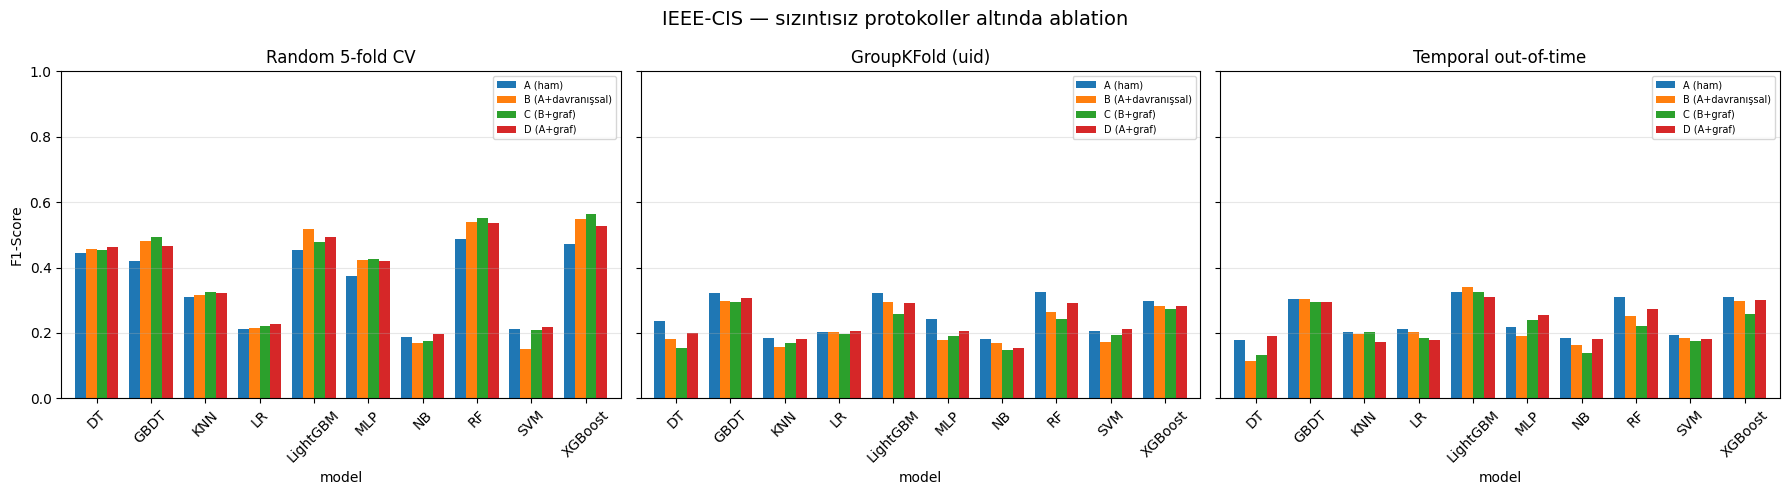

In [31]:
all_res = pd.concat([res_random, res_group, res_temporal], ignore_index=True)
all_res.to_csv('ieee_results_all_protocols.csv', index=False)

gain = []
for proto in all_res['protocol'].unique():
    s = all_res[all_res.protocol==proto]
    p = s.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')
    for m in p.index:
        gain.append({'protocol':proto,'model':m,
                     'B-A (davranışsal)':round(p.loc[m,'B (A+davranışsal)']-p.loc[m,'A (ham)'],4),
                     'D-A (saf graf)'   :round(p.loc[m,'D (A+graf)']-p.loc[m,'A (ham)'],4),
                     'C-B (graf net)'   :round(p.loc[m,'C (B+graf)']-p.loc[m,'B (A+davranışsal)'],4)})
gain_df = pd.DataFrame(gain)
print('='*115)
print('KATKI AYRIŞTIRMASI — hangi öznitelik grubu ne kadar katkı sağlıyor?')
print('='*115)
print(gain_df.pivot_table(index='model', columns='protocol',
      values=['B-A (davranışsal)','D-A (saf graf)','C-B (graf net)']).round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for ax, proto in zip(axes, all_res['protocol'].unique()):
    s = all_res[all_res.protocol==proto]
    p = s.pivot_table(index='model', columns='feature_set', values='f1', aggfunc='mean')[order]
    p.plot(kind='bar', ax=ax, width=.8)
    ax.set_title(proto, fontsize=12); ax.set_ylabel('F1-Score'); ax.set_ylim(0,1)
    ax.legend(fontsize=7); ax.grid(axis='y', alpha=.3); ax.tick_params(axis='x', rotation=45)
plt.suptitle('IEEE-CIS — sızıntısız protokoller altında ablation', fontsize=14)
plt.tight_layout(); plt.show()

## 13. İstatistiksel Anlamlılık

In [32]:
def paired_test(res, s1, s2, metric='f1'):
    out = []
    for m in res['model'].unique():
        a = res[(res.model==m)&(res.feature_set==s1)].sort_values('fold')[metric].values
        b = res[(res.model==m)&(res.feature_set==s2)].sort_values('fold')[metric].values
        if len(a) < 2 or len(a) != len(b): continue
        d = a - b
        if np.allclose(d, 0):
            out.append({'model':m,'mean_diff':0.0,'p_ttest':1.0,'significant_p<0.05':'no'}); continue
        t_, p_ = stats.ttest_rel(a, b)
        try: _, pw = stats.wilcoxon(a, b)
        except Exception: pw = np.nan
        out.append({'model':m,'mean_diff':round(d.mean(),5),'std_diff':round(d.std(ddof=1),5),
                    't_stat':round(t_,3),'p_ttest':round(p_,4),
                    'p_wilcoxon':round(pw,4) if not np.isnan(pw) else np.nan,
                    'cohens_d':round(d.mean()/d.std(ddof=1),3) if d.std(ddof=1)>0 else np.nan,
                    'significant_p<0.05':'YES' if p_<0.05 else 'no'})
    return pd.DataFrame(out)

for res_, nm in [(res_random,'Random 5-fold'), (res_group,'GroupKFold')]:
    print('='*100); print(f'{nm}: Set C vs Set B (graf net katkısı)'); print('='*100)
    print(paired_test(res_,'C (B+graf)','B (A+davranışsal)').to_string(index=False))
    print(f'\n{nm}: Set D vs Set A (saf graf katkısı)')
    print(paired_test(res_,'D (A+graf)','A (ham)').to_string(index=False))
    print()

Random 5-fold: Set C vs Set B (graf net katkısı)
   model  mean_diff  std_diff  t_stat  p_ttest  p_wilcoxon  cohens_d significant_p<0.05
      LR    0.00502   0.00288   3.897   0.0176      0.0625     1.743                YES
      NB    0.00816   0.00539   3.384   0.0277      0.1250     1.514                YES
      DT   -0.00452   0.02158  -0.468   0.6640      1.0000    -0.209                 no
     KNN    0.00970   0.00530   4.094   0.0149      0.0625     1.831                YES
     SVM    0.05806   0.03145   4.128   0.0145      0.0625     1.846                YES
      RF    0.01340   0.01462   2.050   0.1097      0.1250     0.917                 no
    GBDT    0.01147   0.01109   2.312   0.0818      0.1875     1.034                 no
 XGBoost    0.01552   0.01080   3.213   0.0325      0.0625     1.437                YES
LightGBM   -0.03869   0.09415  -0.919   0.4102      0.8125    -0.411                 no
     MLP    0.00354   0.03235   0.245   0.8187      1.0000     0.109   

### Düzeltilmiş istatistiksel test (B9)

In [33]:
# ============================================================
# B9 — DUZELTILMIS ISTATISTIKSEL TEST
# ------------------------------------------------------------
# CV fold'lari bagimsiz degildir (egitim kumeleri ortusur); duz eslestirilmis
# t-testi varyansi olcmekte eksik kalir ve p-degerlerini oldugundan kucuk verir.
# Nadeau & Bengio (2003) duzeltilmis yeniden ornekleme t-testi:
#     t = mean(d) / sqrt((1/k + n_test/n_train) * var(d)),  df = k - 1
# 10 model ayni karsilastirmada test edildigi icin Holm (1979) duzeltmesi uygulanir.
# Protokol 3 tek bolme oldugu icin bu testle sinanmaz.
# ============================================================
B9_COMPARISONS = [('C (B+graf)', 'B (A+davranışsal)'), ('D (A+graf)', 'A (ham)'), ('B (A+davranışsal)', 'A (ham)')]
B9_METRICS     = ['f1', 'pr_auc']
B9_ALPHA       = 0.05

def corrected_resampled_ttest(a, b, test_train_ratio):
    d = np.asarray(a, float) - np.asarray(b, float); k = len(d); v = d.var(ddof=1)
    if v == 0:
        return d.mean(), np.nan, 1.0
    t = d.mean() / np.sqrt((1.0 / k + test_train_ratio) * v)
    return d.mean(), t, float(2 * stats.t.sf(abs(t), df=k - 1))

def holm_adjust(pvals):
    p = np.nan_to_num(np.asarray(pvals, float), nan=1.0); m = len(p)
    adj, run = np.empty(m), 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, min(1.0, (m - r) * p[i])); adj[i] = run
    return adj

def significance_table(res, splits, protocol):
    ratio = float(np.mean([len(te) / len(tr) for tr, te in splits]))
    rows = []
    for s1, s2 in B9_COMPARISONS:
        for met in B9_METRICS:
            block = []
            for m in sorted(res['model'].unique()):
                a = res[(res.model == m) & (res.feature_set == s1)].sort_values('fold')[met].values
                b = res[(res.model == m) & (res.feature_set == s2)].sort_values('fold')[met].values
                if len(a) < 2 or len(a) != len(b):
                    continue
                diff, t, p = corrected_resampled_ttest(a, b, ratio)
                p_naive = stats.ttest_rel(a, b).pvalue if np.std(a - b) > 0 else 1.0
                block.append({'protocol': protocol, 'comparison': f'{s1} vs {s2}', 'metric': met, 'model': m,
                              'mean_diff': diff, 't_corr': t, 'p_naive': p_naive, 'p_corr': p})
            for r, pa in zip(block, holm_adjust([r['p_corr'] for r in block])):
                r['p_holm'] = pa
                r['naive_sig'] = r['p_naive'] < B9_ALPHA
                r['holm_sig']  = pa < B9_ALPHA
            rows += block
    return pd.DataFrame(rows)

sig_corrected = pd.concat([significance_table(res_random, splits_random, 'P1'),
                           significance_table(res_group,  splits_group,  'P2')], ignore_index=True)
sig_corrected.to_csv(f'significance_corrected_{PIPELINE_VERSION}.csv', index=False)

_sum = (sig_corrected.groupby(['protocol', 'comparison', 'metric'])
        .agg(ort_fark=('mean_diff', 'mean'), anlamli_naive=('naive_sig', 'sum'), anlamli_duzeltilmis_holm=('holm_sig', 'sum'),
             model=('model', 'count')).round(4))
print('=' * 100); print('B9 — Anlamli model sayisi: duz t-testi vs duzeltilmis t-testi + Holm'); print('=' * 100)
print(_sum.to_string()); print()
for (pr, cmp_, met), blk in sig_corrected.groupby(['protocol', 'comparison', 'metric']):
    if met != 'f1': continue
    print(f'--- {pr} | {cmp_} | F1')
    print(blk[['model', 'mean_diff', 't_corr', 'p_naive', 'p_corr', 'p_holm', 'holm_sig']].round(4).to_string(index=False)); print()


B9 — Anlamli model sayisi: duz t-testi vs duzeltilmis t-testi + Holm
                                                 ort_fark  anlamli_naive  anlamli_duzeltilmis_holm  model
protocol comparison                      metric                                                          
P1       B (A+davranışsal) vs A (ham)    f1        0.0248              7                         4     10
                                         pr_auc    0.0525              7                         6     10
         C (B+graf) vs B (A+davranışsal) f1        0.0082              5                         0     10
                                         pr_auc    0.0032              7                         2     10
         D (A+graf) vs A (ham)           f1        0.0294             10                         6     10
                                         pr_auc    0.0449              9                         6     10
P2       B (A+davranışsal) vs A (ham)    f1       -0.0321              4           

## 14. Sınıf Dengesizliği Stratejileri

In [34]:
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

SAMPLING_RATIO = 1/3   # B10: tum yontemler ayni hedef azinlik/cogunluk orani
SAMPLER_TAG_SUFFIX = {'SMOTETomek': '_B10'}   # yapilandirmasi degisen yontem yeniden kosulur

SAMPLERS = {
    'None'       : None,
    'RandomUnder': RandomUnderSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED),
    'NearMiss'   : NearMiss(version=1, sampling_strategy=SAMPLING_RATIO),
    'SMOTE'      : SMOTE(sampling_strategy=SAMPLING_RATIO, k_neighbors=5, random_state=SEED),
    'SMOTETomek' : SMOTETomek(sampling_strategy=SAMPLING_RATIO, random_state=SEED),
}
best_set = 'C (B+graf)'
rows = []
for sname, samp in SAMPLERS.items():
    print(f'  Strateji: {sname}', flush=True)
    r, _ = run_protocol(splits_random[:SAMPLING_FOLDS], df, {best_set: FEATURE_SETS[best_set]},
                        model_names=['RF'], sampler=samp,
                        label=f'sampling={sname}', tag=f'S_{sname}{SAMPLER_TAG_SUFFIX.get(sname, "")}', verbose=False)
    agg = r[['accuracy','precision','recall','f1','auc_roc','pr_auc','mcc','fpr']].mean().round(4)
    agg['strategy'] = sname
    rows.append(agg)

samp_df = pd.DataFrame(rows).set_index('strategy')
print('='*100); print('SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C)'); print('='*100)
print(samp_df.to_string())
samp_df.to_csv('ieee_results_sampling.csv')

  Strateji: None
  [DEVAM] S_None: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3)]
  Strateji: RandomUnder
  [DEVAM] S_RandomUnder: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3)]
  Strateji: NearMiss
  [DEVAM] S_NearMiss: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3)]
  Strateji: SMOTE
  [DEVAM] S_SMOTE: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3)]
  Strateji: SMOTETomek
  [DEVAM] S_SMOTETomek_B10: tamamlanmış fold = [np.int64(1), np.int64(2), np.int64(3)]
SINIF DENGESİZLİĞİ STRATEJİLERİ (RF + Set C)
             accuracy  precision  recall      f1  auc_roc  pr_auc     mcc     fpr
strategy                                                                         
None           0.9715     0.6004  0.5177  0.5521   0.9240  0.5915  0.5412  0.0126
RandomUnder    0.9169     0.2561  0.7375  0.3787   0.9214  0.5171  0.4025  0.0768
NearMiss       0.3444     0.0384  0.7644  0.0731   0.5751  0.1011  0.0363  0.6703
SMOTE          0.9506     0.3693  0

## 15. En İyi Modelin Detaylı Analizi (zamansal protokol)

In [35]:
best_model_name = p3['C (B+graf)'].idxmax()
print(f'Zamansal protokolde en iyi model: {best_model_name}')

d_tr, d_te = df[df.TransactionDT<=TEMPORAL_CUT], df[df.TransactionDT>TEMPORAL_CUT]
f_tr, f_te, tinfo_best = compute_fold_features(d_tr, d_te)
y_tr, y_te = f_tr['isFraud'].values, f_te['isFraud'].values

feats_C = [c for c in FEATURE_SETS['C (B+graf)'] if c in f_tr.columns]
Xtr = np.nan_to_num(f_tr[feats_C].astype(np.float64).values, nan=0.0, posinf=0.0, neginf=0.0)
Xte = np.nan_to_num(f_te[feats_C].astype(np.float64).values, nan=0.0, posinf=0.0, neginf=0.0)

# Eşik seçimi dahil tüm adımlar fit_predict içinde, yalnızca eğitim verisinden
best_model = get_models()[best_model_name]
yp, ys, fit_s, best_thr = fit_predict(best_model, Xtr, y_tr, Xte,
                                      model_name=best_model_name)

print(f'Eğitim fold\'unda seçilen eşik: {best_thr:.4f}  (sabit 0.5 yerine)')
print(f'Eğitim süresi: {fit_s:.1f}s')

print('\n' + classification_report(y_te, yp, target_names=['Normal','Fraud'], digits=4))
met = full_metrics(y_te, yp, ys)
for k, v in met.items():
    print(f'  {k:22s}: {v:.4f}' if isinstance(v, float) else f'  {k:22s}: {v}')

# Karşılaştırma: sabit 0.5 eşiği ne verirdi?
yp_fixed = (ys >= 0.5).astype(int)
met_fixed = full_metrics(y_te, yp_fixed, ys)
print('\n' + '='*70)
print('EŞİK SEÇİMİNİN ETKİSİ')
print('='*70)
cmp_thr = pd.DataFrame({
    'Sabit 0.5':      {k: round(met_fixed[k],4) for k in ['precision','recall','f1','mcc','fpr']},
    f'Seçilen {best_thr:.3f}': {k: round(met[k],4) for k in ['precision','recall','f1','mcc','fpr']},
})
print(cmp_thr.to_string())
print('\nNOT: AUC-ROC ve PR-AUC eşikten bağımsızdır, değişmez.')
print(f'  AUC-ROC={met["auc_roc"]:.4f}  PR-AUC={met["pr_auc"]:.4f}')

Zamansal protokolde en iyi model: LightGBM
    graf=2.3s cent=224.6s uygula=5.2s | düğüm=70,491 kenar=185,745 topluluk=33 görülmeyen varlık=%55.9 kappa=0.441 impute=row_median
Eğitim fold'unda seçilen eşik: 0.1905  (sabit 0.5 yerine)
Eğitim süresi: 8.0s

              precision    recall  f1-score   support

      Normal     0.9761    0.9881    0.9820     38725
       Fraud     0.4225    0.2651    0.3258      1275

    accuracy                         0.9650     40000
   macro avg     0.6993    0.6266    0.6539     40000
weighted avg     0.9585    0.9650    0.9611     40000

  accuracy              : 0.9650
  precision             : 0.4225
  recall                : 0.2651
  f1                    : 0.3258
  auc_roc               : 0.8687
  pr_auc                : 0.3090
  mcc                   : 0.3177
  fpr                   : 0.0119
  precision_at_1pct     : 0.5450
  recall_at_1pct        : 0.1710
  tn                    : 38263
  fp                    : 462
  fn                    : 

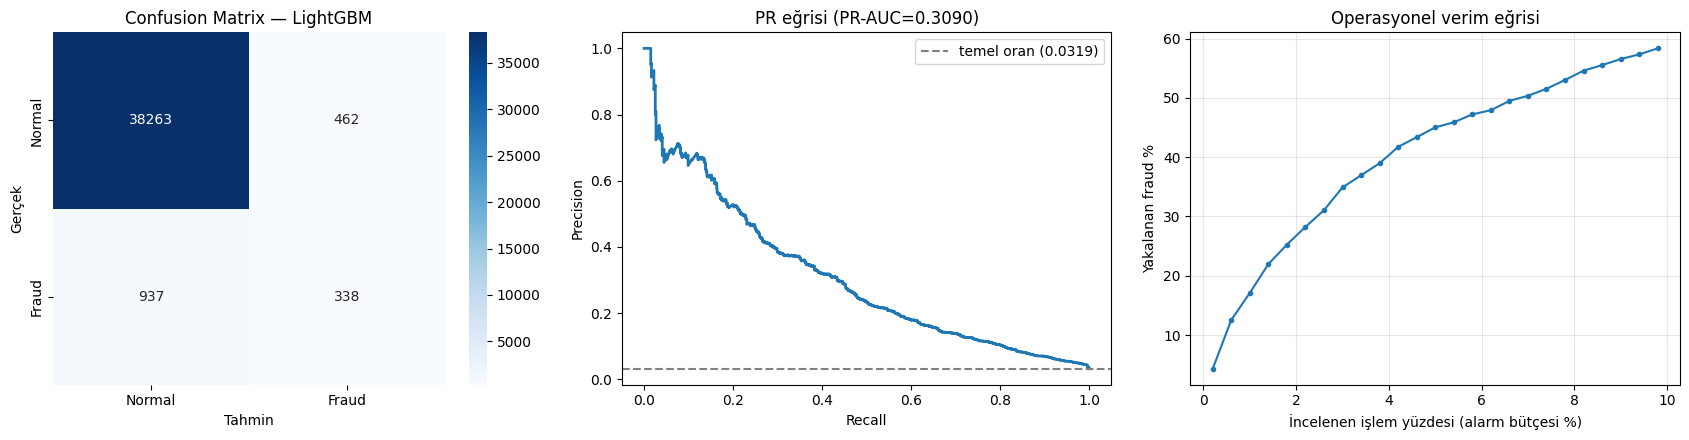

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.5))

cm = confusion_matrix(y_te, yp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Normal','Fraud'], yticklabels=['Normal','Fraud'])
ax[0].set_title(f'Confusion Matrix — {best_model_name}')
ax[0].set_xlabel('Tahmin'); ax[0].set_ylabel('Gerçek')

prec, rec, _ = precision_recall_curve(y_te, ys)
ax[1].plot(rec, prec, lw=2)
ax[1].axhline(y_te.mean(), ls='--', c='gray', label=f'temel oran ({y_te.mean():.4f})')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title(f'PR eğrisi (PR-AUC={met["pr_auc"]:.4f})'); ax[1].legend()

ks = np.arange(0.002, 0.101, 0.004)
caught = [y_te[np.argsort(-ys)[:max(1,int(len(y_te)*k))]].sum()/y_te.sum() for k in ks]
ax[2].plot(ks*100, np.array(caught)*100, marker='o', ms=3)
ax[2].set_xlabel('İncelenen işlem yüzdesi (alarm bütçesi %)')
ax[2].set_ylabel('Yakalanan fraud %')
ax[2].set_title('Operasyonel verim eğrisi'); ax[2].grid(alpha=.3)

plt.tight_layout(); plt.show()

## 16. SHAP — Kategori Bazında Katkı

SHAP modeli: LightGBM

En önemli 15 öznitelik:
             feature  mean_abs_shap         category
     ent_time_span_d       0.246561 Behavioral (B\A)
   R_emaildomain_enc       0.236868          Raw (A)
        ent_velocity       0.182121 Behavioral (B\A)
                  D2       0.167113          Raw (A)
               card3       0.139230          Raw (A)
                  D3       0.136511          Raw (A)
           card6_enc       0.116407          Raw (A)
  amount_to_addr_avg       0.103627 Behavioral (B\A)
       ProductCD_enc       0.095135          Raw (A)
      ent_avg_amount       0.065481 Behavioral (B\A)
                 D15       0.065412          Raw (A)
      TransactionAmt       0.061958          Raw (A)
community_fraud_rate       0.053687      Graph (C\B)
        card1_degree       0.053404      Graph (C\B)
   P_emaildomain_enc       0.052212          Raw (A)

KATEGORİ BAZINDA SHAP KATKI PAYI
                      sum  count  share_%
category                     

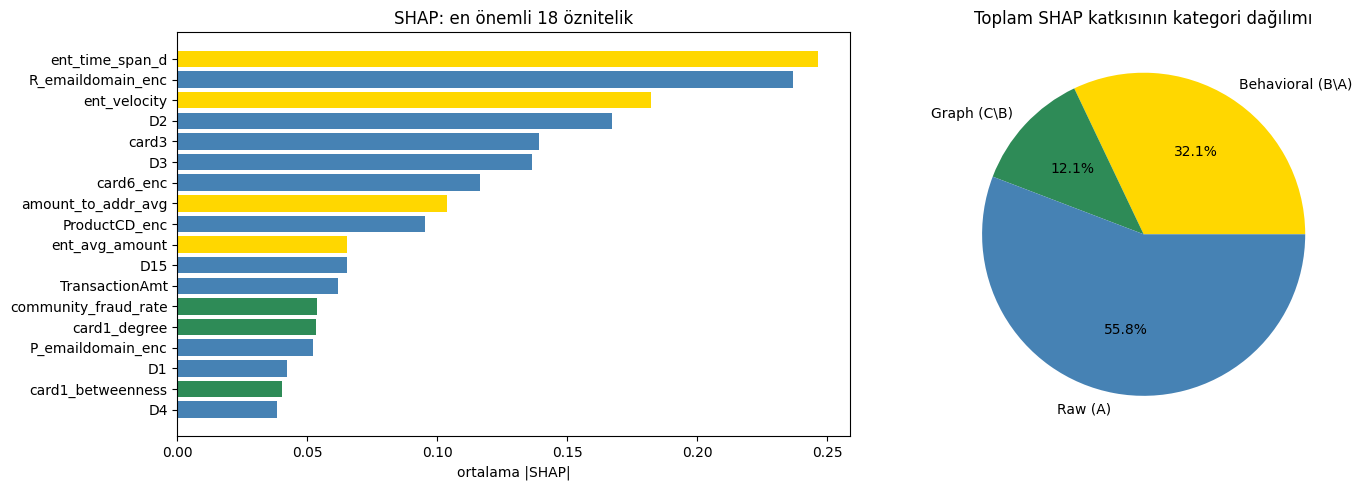

In [37]:
try:
    import shap
    shap_model = best_model_name if best_model_name in ['RF','XGBoost','LightGBM','GBDT','DT'] else 'LightGBM'
    print(f'SHAP modeli: {shap_model}')
    # Olcekleme yalnizca egitimden fit edilir (fit_predict ile ayni mantik).
    # Xtr_s/Xte_s fit_predict icinde yerel oldugu icin burada acikca uretilir.
    from sklearn.preprocessing import StandardScaler
    _sc = StandardScaler().fit(Xtr)
    Xtr_s, Xte_s = _sc.transform(Xtr), _sc.transform(Xte)
    m = get_models()[shap_model]; m.fit(Xtr_s, y_tr)

    n_s = min(5000, len(Xte_s))
    idx = np.random.RandomState(SEED).choice(len(Xte_s), n_s, replace=False)
    sv = shap.TreeExplainer(m).shap_values(Xte_s[idx])
    if isinstance(sv, list): sv = sv[1]
    if sv.ndim == 3: sv = sv[:,:,1]

    imp = pd.DataFrame({'feature':feats_C, 'mean_abs_shap':np.abs(sv).mean(axis=0)})
    def _cat(f):
        if f in BEHAVIORAL:   return 'Behavioral (B\\A)'
        if f in GRAPH_FEATS:  return 'Graph (C\\B)'
        return 'Raw (A)'
    imp['category'] = imp['feature'].map(_cat)
    imp = imp.sort_values('mean_abs_shap', ascending=False)
    print('\nEn önemli 15 öznitelik:'); print(imp.head(15).to_string(index=False))

    ct = imp.groupby('category')['mean_abs_shap'].agg(['sum','count'])
    ct['share_%'] = (ct['sum']/ct['sum'].sum()*100).round(2)
    print('\n' + '='*70); print('KATEGORİ BAZINDA SHAP KATKI PAYI'); print('='*70)
    print(ct.round(5).to_string())
    # BankSim karsilastirmasi sabit sayi yerine BankSim notebook'unun ciktisindan okunur
    BANKSIM_SHAP_CSV = 'shap_importance.csv'
    if os.path.exists(BANKSIM_SHAP_CSV):
        _b = pd.read_csv(BANKSIM_SHAP_CSV).groupby('category')['mean_abs_shap'].sum()
        print('\nKARŞILAŞTIRMA — BankSim: ' + ', '.join(f'{k} %{v/_b.sum()*100:.1f}' for k, v in _b.items()))
    else:
        print(f'\n(BankSim karşılaştırması için {BANKSIM_SHAP_CSV} bulunamadı)')
    imp.to_csv('ieee_shap_importance.csv', index=False)

    fig, ax = plt.subplots(1, 2, figsize=(15,5))
    colors = {'Raw (A)':'steelblue','Behavioral (B\\A)':'gold','Graph (C\\B)':'seagreen'}
    top = imp.head(18).iloc[::-1]
    ax[0].barh(top['feature'], top['mean_abs_shap'], color=[colors[c] for c in top['category']])
    ax[0].set_title('SHAP: en önemli 18 öznitelik'); ax[0].set_xlabel('ortalama |SHAP|')
    ax[1].pie(ct['sum'], labels=ct.index, autopct='%1.1f%%',
              colors=[colors[c] for c in ct.index])
    ax[1].set_title('Toplam SHAP katkısının kategori dağılımı')
    plt.tight_layout(); plt.show()
except ImportError:
    print('shap kurulu değil: pip install shap')

## 17. Hesaplama Maliyeti

"Graf öznitelik mühendisliği GNN'e göre hızlıdır" iddiasının ölçümle
desteklenmesi

In [38]:
tim_all = pd.concat([tim_random.assign(protocol='Random 5-fold'),
                     tim_group.assign(protocol='GroupKFold'),
                     tim_temporal.assign(protocol='Temporal')], ignore_index=True)

summ = tim_all.groupby('protocol')[['graph_build_s','centrality_s','apply_s',
                                    'n_nodes','n_edges','n_communities',
                                    'unseen_entity_frac', 'kappa']].mean().round(3)
print('='*95); print('GRAF ÖZNİTELİK ÇIKARIM MALİYETİ'); print('='*95)
print(summ.to_string())

alg_cols = [c for c in tim_all.columns if c.startswith('alg_') and c.endswith('_s')]
per_alg = tim_all[alg_cols].mean().round(3).sort_values(ascending=False)
per_alg.index = [c[4:-2] for c in per_alg.index]
print('\nAlgoritma bazlı ortalama süre (saniye):'); print(per_alg.to_string())

total_extract = float(summ[['graph_build_s','centrality_s','apply_s']].sum(axis=1).mean())
print(f'\nToplam çıkarım süresi : {total_extract:.2f} s')
print(f'İşlem sayısı          : {len(df):,}')
print(f'Verim                 : {len(df)/total_extract:,.0f} işlem/saniye')
print(f'İşlem başına maliyet  : {total_extract/len(df)*1e6:.2f} mikrosaniye')
BANKSIM_TIMING_JSON = 'timing_analysis.json'   # BankSim notebook'unun ciktisi
if os.path.exists(BANKSIM_TIMING_JSON):
    _bt = json.load(open(BANKSIM_TIMING_JSON))
    print(f"\nKARŞILAŞTIRMA — BankSim: {_bt['tx_per_second']:,.0f} işlem/saniye")
else:
    print(f'\n(BankSim karşılaştırması için {BANKSIM_TIMING_JSON} bulunamadı)')

fit_summ = all_res.groupby(['model','feature_set'])['fit_s'].mean().unstack().round(2)
print('\nModel eğitim süreleri (saniye):'); print(fit_summ.to_string())

json.dump({'feature_extraction':summ.to_dict(),'per_algorithm_s':per_alg.to_dict(),
           'total_extract_s':total_extract,'tx_per_second':len(df)/total_extract,
           'fast_mode':FAST_MODE,'subsample_n':SUBSAMPLE_N,'knn_cap':KNN_TRAIN_CAP,
           'hyperparameters':HYPERPARAMS},
          open('ieee_timing_analysis.json','w'), indent=2, default=str)
print('\nieee_timing_analysis.json kaydedildi.')

GRAF ÖZNİTELİK ÇIKARIM MALİYETİ
               graph_build_s  centrality_s  apply_s  n_nodes   n_edges  n_communities  unseen_entity_frac  kappa
protocol                                                                                                        
GroupKFold             1.884       227.422    7.355  67299.6  176945.6           33.8               1.000  0.000
Random 5-fold          1.903       204.040    4.707  73275.2  192886.8           34.2               0.241  0.759
Temporal               1.618       197.881    6.546  70491.0  185745.0           33.0               0.559  0.441

Algoritma bazlı ortalama süre (saniye):
betweenness    201.922
louvain         11.288
pagerank         0.585
degree           0.167
eigenvector      0.147

Toplam çıkarım süresi : 217.79 s
İşlem sayısı          : 200,000
Verim                 : 918 işlem/saniye
İşlem başına maliyet  : 1088.93 mikrosaniye

(BankSim karşılaştırması için timing_analysis.json bulunamadı)

Model eğitim süreleri (saniye):

## 18. Makale Tabloları ve Özet

In [39]:
tables = {
    'T1_feature_categories': feature_map_df.groupby(['Category','Present in sets']).size().reset_index(name='# features'),
    'T0_audit_criteria'   : audit_table,   # A6
    'T2_audit_single_feat' : scan.head(20),
    'T3_audit_rules'       : rule_df,
    'T4_audit_degenerate'  : deg_df,
    'T5_audit_vesta_overlap': overlap_df,
    'T6_sampling'          : samp_df,
    'T7_random_cv'         : p1,
    'T8_groupkfold'        : p2,
    'T9_temporal'          : p3,
    'T10_significance_CB'  : paired_test(res_random,'C (B+graf)','B (A+davranışsal)'),
    'T11_significance_DA'  : paired_test(res_random,'D (A+graf)','A (ham)'),
    'T12_timing'           : summ,
}
if 'c_kappa_counts' in globals() and len(c_kappa_counts):
    tables['T17_c_kappa_counts'] = c_kappa_counts
for _k, _t in (globals().get('p4_tables') or {}).items():
    tables[f'T18_P4_{_k}'] = _t
for _nm, _var in [('T10b_significance_corrected', 'sig_corrected'), ('T13_leakage_injection', 'leak_table'),
                  ('T14_a8_strong_baseline', 'a8_res'),
                  ('T15_c_solution_f1', None), ('T16_c_solution_prauc', None)]:
    if _var is None:
        if 'c_tables' in globals():
            tables[_nm] = c_tables['f1' if 'f1' in _nm else 'pr_auc']
        continue
    if _var in globals():
        tables[_nm] = globals()[_var]

with pd.ExcelWriter('paper_tables_ieee.xlsx') as w:
    for n, t in tables.items():
        t.to_excel(w, sheet_name=n[:31])
print('paper_tables_ieee.xlsx kaydedildi.\n')

print('='*100); print('IEEE-CIS — ANA BULGULAR (sızıntısız)'); print('='*100)
print(f'''
VERİ
  İşlem      : {len(df):,} (prevalans korundu: %{df['isFraud'].mean()*100:.3f})
  Graf       : {summ['n_nodes'].mean():,.0f} düğüm, {summ['n_edges'].mean():,.0f} kenar
  Kenar tanımı: {GRAPH_RELATIONS}

ARTEFAKT DENETİMİ
  En yüksek tek öznitelik AUC : {scan.iloc[0]['auc']:.4f} ({scan.iloc[0]['feature']})
  En iyi basit kural F1       : {rule_df['F1'].max():.4f}
  (PaySim referans: kural F1=0.9890 -> reddedilmişti)
''')
for nm, p in [('Rastgele 5-fold CV', p1), (f'GroupKFold ({ENTITY_COL})', p2), ('Zamansal', p3)]:
    bm = p['C (B+graf)'].idxmax()
    print(f'{nm}:')
    print(f'  En iyi model / F1    : {bm} / {p.loc[bm,"C (B+graf)"]:.4f}')
    print(f'  Ortalama B-A         : {(p["B (A+davranışsal)"]-p["A (ham)"]).mean():+.4f}')
    print(f'  Ortalama D-A (graf)  : {p["D-A"].mean():+.4f}')
    print(f'  Ortalama C-B (graf)  : {p["C-B"].mean():+.4f}')
    print()
if 'p4_tables' in globals():
    _d = p4_tables['diff_pr_auc'].groupby(level='karsilastirma')['ort_fark'].mean()
    print('Rolling-origin (P4), PR-AUC farklari (modellerin ortalamasi):')
    for _n in ['D−A', 'Router C|A − A', 'D_full−A_full', 'C_full−B_full', 'Router C_full|A_full − A_full']:
        if _n in _d: print(f'  {_n:32s}: {_d[_n]:+.4f}')
    print()
print(f'Hesaplama: {total_extract:.1f}s çıkarım, {len(df)/total_extract:,.0f} işlem/saniye')

paper_tables_ieee.xlsx kaydedildi.

IEEE-CIS — ANA BULGULAR (sızıntısız)

VERİ
  İşlem      : 200,000 (prevalans korundu: %3.382)
  Graf       : 70,355 düğüm, 185,192 kenar
  Kenar tanımı: [('uid', 'card1'), ('uid', 'addr1'), ('uid', 'P_emaildomain')]

ARTEFAKT DENETİMİ
  En yüksek tek öznitelik AUC : 0.6890 (C4)
  En iyi basit kural F1       : 0.3462
  (PaySim referans: kural F1=0.9890 -> reddedilmişti)

Rastgele 5-fold CV:
  En iyi model / F1    : XGBoost / 0.5647
  Ortalama B-A         : +0.0248
  Ortalama D-A (graf)  : +0.0294
  Ortalama C-B (graf)  : +0.0082

GroupKFold (uid):
  En iyi model / F1    : GBDT / 0.2955
  Ortalama B-A         : -0.0321
  Ortalama D-A (graf)  : -0.0187
  Ortalama C-B (graf)  : -0.0077

Zamansal:
  En iyi model / F1    : LightGBM / 0.3258
  Ortalama B-A         : -0.0196
  Ortalama D-A (graf)  : -0.0106
  Ortalama C-B (graf)  : -0.0067

Rolling-origin (P4), PR-AUC farklari (modellerin ortalamasi):
  D−A                             : +0.0421
  Router C|A 